# County-Level Maize (Corn) Grain Yield Prediction

**Target Variable:** `corn_yield_bu_acre` (bushels per acre)  
**Problem Type:** Supervised Machine Learning — Regression  
**Study Area & Years:** 9 US Corn Belt states (`IA`, `IL`, `IN`, `MN`, `MO`, `NE`, `OH`, `SD`, `WI`), `2002–2025`  
**GitHub Repository:** `https://github.com/ayankhan96686-create/ml-pbl.git`

## 1. Project Introduction

Maize yield prediction estimates how much corn grain each county will produce in bushels per acre (`bu/acre`) using weather, soil, and agricultural conditions. Accurate yield forecasts help farmers, grain storage operators, and crop insurance planners prepare for good harvests as well as drought losses.

Because crop yield depends on multiple factors at once, we combine several real-world datasets:
- **USDA NASS Corn Grain Yield:** Historical county-level maize yield (`corn_yield_bu_acre`), our target variable.
- **NOAA ClimDiv Climate Data:** Monthly county temperature and precipitation across the growing season (`May–September`).
- **PRISM Climate Data:** Gridded county climate summaries (`2002–2025` annual summaries and `2026` provisional monthly values).
- **ISRIC SoilGrids:** Static county soil properties (`clay`, `sand`, `silt`, `soc`, `phh2o`, `bdod` across `0–30 cm`).
- **USDA RMA Crop Insurance:** County-year planted acres, insurance liability, premiums, and subsidies.
- **USDA NASS Crop Condition & Progress:** State-level weekly crop health and growth-stage progress aggregated by year.

Notice that folders such as `ERA5-Land`, `MODIS`, `Landsat`, `Sentinel-2`, and `gSSURGO` in the original inventory did not contain actual data files, so this notebook uses only the real available datasets above.

## 2. Import Libraries and Read Datasets from GitHub

If you are running this notebook in a fresh environment (such as Google Colab), install the project packages first:
```bash
pip install -r requirements.txt
```
Below we import the core Python, visualization, statistical, and Scikit-learn libraries. Optional gradient-boosting packages (`xgboost`, `lightgbm`, `catboost`) are imported safely so the notebook still runs if any of them is not installed.

In [1]:
import os
import sys
import subprocess
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
import statsmodels.api as sm

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import f_regression

from sklearn.linear_model import LinearRegression, Ridge, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    RandomForestClassifier,
)

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
)

# Optional boosting models: handle missing packages cleanly
try:
    import xgboost as xgb
except ImportError:
    xgb = None
    print("Optional package 'xgboost' not found. Install with: pip install xgboost")

try:
    import lightgbm as lgb
except ImportError:
    lgb = None
    print("Optional package 'lightgbm' not found. Install with: pip install lightgbm")

try:
    from catboost import CatBoostRegressor
except ImportError:
    CatBoostRegressor = None
    print("Optional package 'catboost' not found. Install with: pip install catboost")

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 120

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Core libraries imported successfully.")
print(
    "Optional models available ->",
    f"XGBoost: {xgb is not None}, LightGBM: {lgb is not None}, CatBoost: {CatBoostRegressor is not None}"
)

Core libraries imported successfully.
Optional models available -> XGBoost: True, LightGBM: True, CatBoost: True


### Load Datasets from the GitHub Repository
The code below looks for the `data/` directory inside the current repository first. If it is not found locally (for example, when opened standalone in Google Colab), it clones `https://github.com/ayankhan96686-create/ml-pbl.git` once and loads every dataset from `data/`.

In [2]:
REPO_URL = "https://github.com/ayankhan96686-create/ml-pbl.git"
cwd = Path.cwd().resolve()

# Detect local repository root if already cloned
candidate_roots = [
    cwd,
    cwd.parent,
    cwd / "ml-pbl",
    cwd.parent / "ml-pbl",
]

REPO_DIR = None
for cand in candidate_roots:
    if (cand / "data" / "processed" / "cleaned" / "USDA_Yield_Cleaned.csv").exists():
        REPO_DIR = cand
        break

if REPO_DIR is None:
    REPO_DIR = cwd / "ml-pbl"
    if not REPO_DIR.exists():
        print(f"Cloning dataset repository from {REPO_URL} ...")
        subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)
    # Pull any Git LFS files if git-lfs is installed
    try:
        subprocess.run(["git", "-C", str(REPO_DIR), "lfs", "pull"], check=False)
    except FileNotFoundError:
        pass

DATA_DIR = REPO_DIR / "data"
RAW_DIR = DATA_DIR / "raw"
CLEAN_DIR = DATA_DIR / "processed" / "cleaned"
INT_DIR = DATA_DIR / "processed" / "integrated"
OUTPUT_DIR = (REPO_DIR / "outputs") if (REPO_DIR / "outputs").exists() else (cwd / "outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

required_files = {
    "raw_yield": RAW_DIR / "usda_nass" / "USDA_NASS_Corn_Grain_Yield_9States_2002_2026_723B6328-B866-3F54-AB6D-07F62EE064E9.csv",
    "counties_fips": RAW_DIR / "county_boundaries" / "Study_Area_Counties_FIPS.csv",
    "yield": CLEAN_DIR / "USDA_Yield_Cleaned.csv",
    "noaa": CLEAN_DIR / "NOAA_Climate_Cleaned.csv",
    "prism": CLEAN_DIR / "PRISM_Climate_Cleaned.csv",
    "soil": CLEAN_DIR / "SoilGrids_Cleaned.csv",
    "rma": CLEAN_DIR / "RMA_Cleaned.csv",
    "cond": CLEAN_DIR / "Crop_Condition_Cleaned.csv",
    "prog": CLEAN_DIR / "Crop_Progress_Cleaned.csv",
    "manifest": DATA_DIR / "data_manifest.csv",
}

for label, fpath in required_files.items():
    if not fpath.exists():
        raise FileNotFoundError(f"Required file '{label}' missing at: {fpath}")

# Read FIPS columns as strings so leading zeros are never lost
raw_yield_df = pd.read_csv(required_files["raw_yield"], dtype=str)
counties_ref = pd.read_csv(required_files["counties_fips"], dtype=str)
yield_df = pd.read_csv(required_files["yield"], dtype={"county_fips": str})
noaa_df  = pd.read_csv(required_files["noaa"], dtype={"county_fips": str})
prism_df = pd.read_csv(required_files["prism"], dtype={"county_fips": str})
soil_df  = pd.read_csv(required_files["soil"], dtype={"county_fips": str})
rma_df   = pd.read_csv(required_files["rma"], dtype={"county_fips": str, "state_fips": str})
cond_df  = pd.read_csv(required_files["cond"], dtype={"state_fips": str})
prog_df  = pd.read_csv(required_files["prog"], dtype={"state_fips": str})
manifest_df = pd.read_csv(required_files["manifest"])

print(f"Repository Root : {REPO_DIR}")
print(f"Data Directory  : {DATA_DIR}")
print("All required dataset files loaded successfully!")
print("\nRepository Data Manifest Summary (hosting_status):")
display(manifest_df["hosting_status"].value_counts().rename_axis("hosting_status").to_frame("file_count"))

Repository Root : E:\test for ml\ml-pbl
Data Directory  : E:\test for ml\ml-pbl\data
All required dataset files loaded successfully!

Repository Data Manifest Summary (hosting_status):


,file_count
hosting_status,
uploaded_git,203
external_download_only,19
unavailable_source,6
uploaded_lfs,1


### Dataset Structure Preview (`.shape`, `.head()`, `.info()`)
Below we inspect the size, first 5 rows, and column data types of each dataset we will clean and join.

In [3]:
datasets = [
    ("USDA NASS Corn Yield (Cleaned)", yield_df),
    ("NOAA ClimDiv Climate (Cleaned)", noaa_df),
    ("PRISM Climate (Cleaned)", prism_df),
    ("USDA RMA Crop Insurance (Cleaned)", rma_df),
    ("ISRIC SoilGrids (Cleaned)", soil_df),
    ("USDA NASS Crop Condition (Cleaned)", cond_df),
    ("USDA NASS Crop Progress (Cleaned)", prog_df),
]

for title, df_obj in datasets:
    print("=" * 85)
    print(f"{title} | shape = {df_obj.shape}")
    display(df_obj.head())
    df_obj.info()

USDA NASS Corn Yield (Cleaned) | shape = (16390, 6)


,county_fips,state,county,year,corn_yield_bu_acre,cv_percent
0,17001,Illinois,Adams,2002,146.0,NaN
1,17001,Illinois,Adams,2003,171.0,NaN
2,17001,Illinois,Adams,2004,195.0,NaN
3,17001,Illinois,Adams,2005,129.0,NaN
4,17001,Illinois,Adams,2006,129.0,NaN


<class 'pandas.DataFrame'>
RangeIndex: 16390 entries, 0 to 16389
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   county_fips         16390 non-null  str    
 1   state               16390 non-null  str    
 2   county              16390 non-null  str    
 3   year                16390 non-null  int64  
 4   corn_yield_bu_acre  16390 non-null  float64
 5   cv_percent          3730 non-null   float64
dtypes: float64(2), int64(1), str(3)
memory usage: 1.0 MB
NOAA ClimDiv Climate (Cleaned) | shape = (20350, 18)


,county_fips,state,county,year,noaa_prcp_may_in,noaa_prcp_jun_in,noaa_prcp_jul_in,noaa_prcp_aug_in,noaa_prcp_sep_in,noaa_prcp_may_aug_in,noaa_prcp_may_sep_in,noaa_prcp_annual_in,noaa_tmean_may_aug_f,noaa_tmax_jul_f,noaa_tmax_aug_f,noaa_tmax_may_aug_f,noaa_tmin_may_aug_f,noaa_heat_stress_max_f
0,17001,Illinois,Adams County,2002,9.02,4.27,4.05,4.74,0.96,22.08,23.04,39.36,71.80,88.9,85.0,82.07,61.50,88.9
1,17001,Illinois,Adams County,2003,3.37,4.04,5.00,2.94,6.42,15.35,21.77,38.43,70.58,85.9,86.9,81.15,60.00,86.9
2,17001,Illinois,Adams County,2004,5.06,3.11,3.33,9.21,1.17,20.71,21.88,40.02,69.35,82.6,79.4,79.47,59.25,82.6
3,17001,Illinois,Adams County,2005,1.60,2.68,1.55,4.33,3.67,10.16,13.83,29.94,72.80,89.2,87.3,84.40,61.18,89.2
4,17001,Illinois,Adams County,2006,1.59,3.53,2.79,4.14,2.74,12.05,14.79,31.27,72.55,89.7,86.3,83.18,61.92,89.7


<class 'pandas.DataFrame'>
RangeIndex: 20350 entries, 0 to 20349
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   county_fips             20350 non-null  str    
 1   state                   20350 non-null  str    
 2   county                  20350 non-null  str    
 3   year                    20350 non-null  int64  
 4   noaa_prcp_may_in        20350 non-null  float64
 5   noaa_prcp_jun_in        20350 non-null  float64
 6   noaa_prcp_jul_in        20350 non-null  float64
 7   noaa_prcp_aug_in        20350 non-null  float64
 8   noaa_prcp_sep_in        20350 non-null  float64
 9   noaa_prcp_may_aug_in    20350 non-null  float64
 10  noaa_prcp_may_sep_in    20350 non-null  float64
 11  noaa_prcp_annual_in     19536 non-null  float64
 12  noaa_tmean_may_aug_f    20350 non-null  float64
 13  noaa_tmax_jul_f         20350 non-null  float64
 14  noaa_tmax_aug_f         20350 non-null  float64
 

,county_fips,state,county,year,prism_ppt_mm,prism_tmean_c,prism_tmin_c,prism_tmax_c,prism_valid_coverage_pct
0,17001,Illinois,Adams County,2002,1151.26,11.81,6.31,17.31,100.0
1,17001,Illinois,Adams County,2003,1013.78,11.01,5.52,16.49,100.0
2,17001,Illinois,Adams County,2004,1064.84,11.35,6.09,16.61,100.0
3,17001,Illinois,Adams County,2005,711.53,12.24,6.77,17.72,100.0
4,17001,Illinois,Adams County,2006,768.18,12.43,6.91,17.94,100.0


... (5 outputs left out)

,year,state,state_name,state_fips,state_cond_excellent_mean,state_cond_good_mean,state_cond_fair_mean,state_cond_poor_mean,state_cond_very_poor_mean,state_cond_good_excellent_mean,state_cond_poor_very_poor_mean,state_cond_rep_good_excellent_mean,state_cond_rep_poor_very_poor_mean
0,2002,IA,IOWA,19,17.60,48.65,23.60,7.70,2.45,66.25,10.15,61.71,13.00
1,2003,IA,IOWA,19,15.52,46.24,24.90,9.57,3.76,61.76,13.33,73.43,7.43
2,2004,IA,IOWA,19,22.27,51.09,18.86,5.77,2.00,73.36,7.77,76.29,7.00
3,2005,IA,IOWA,19,20.55,49.77,20.95,6.50,2.23,70.32,8.73,68.00,10.57
4,2006,IA,IOWA,19,20.35,48.70,22.22,6.39,2.35,69.04,8.74,62.86,12.57


<class 'pandas.DataFrame'>
RangeIndex: 225 entries, 0 to 224
Data columns (total 13 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   year                                225 non-null    int64  
 1   state                               225 non-null    str    
 2   state_name                          225 non-null    str    
 3   state_fips                          225 non-null    str    
 4   state_cond_excellent_mean           225 non-null    float64
 5   state_cond_good_mean                225 non-null    float64
 6   state_cond_fair_mean                225 non-null    float64
 7   state_cond_poor_mean                225 non-null    float64
 8   state_cond_very_poor_mean           225 non-null    float64
 9   state_cond_good_excellent_mean      225 non-null    float64
 10  state_cond_poor_very_poor_mean      225 non-null    float64
 11  state_cond_rep_good_excellent_mean  225 non-null    floa

,year,state_name,state_fips,state,state_progress_planted_w20_pct,state_progress_emerged_w22_pct,state_progress_silking_w30_pct,state_progress_dough_w34_pct,state_progress_dented_w37_pct,state_progress_mature_w40_pct,state_progress_week_50pct_planted,state_progress_week_50pct_silking,state_progress_week_50pct_mature,state_progress_postharvest_harvested_w44_pct
0,2002,IOWA,19,IA,94.0,93.0,86.0,83.0,97.0,99.0,18.0,29.0,37.0,76.0
1,2003,IOWA,19,IA,79.0,85.0,67.0,71.0,93.0,97.0,18.0,30.0,37.0,91.0
2,2004,IOWA,19,IA,98.0,98.0,73.0,62.0,81.0,85.0,18.0,30.0,39.0,62.0
3,2005,IOWA,19,IA,98.0,98.0,93.0,91.0,98.0,99.0,17.0,29.0,37.0,91.0
4,2006,IOWA,19,IA,98.0,99.0,94.0,93.0,98.0,99.0,17.0,29.0,37.0,84.0


<class 'pandas.DataFrame'>
RangeIndex: 225 entries, 0 to 224
Data columns (total 14 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   year                                          225 non-null    int64  
 1   state_name                                    225 non-null    str    
 2   state_fips                                    225 non-null    str    
 3   state                                         225 non-null    str    
 4   state_progress_planted_w20_pct                225 non-null    float64
 5   state_progress_emerged_w22_pct                225 non-null    float64
 6   state_progress_silking_w30_pct                225 non-null    float64
 7   state_progress_dough_w34_pct                  225 non-null    float64
 8   state_progress_dented_w37_pct                 225 non-null    float64
 9   state_progress_mature_w40_pct                 207 non-null    float64
 10  s

**Important note on PRISM time coverage:**  
Let us compare the average `2002–2025` PRISM values with the provisional `2026` PRISM values. In `PRISM_Climate_Cleaned.csv`, the historical `2002–2025` temperature columns are **annual 12-month averages** (including cold winter and post-harvest months), whereas `2026` was aggregated over May–October only and `2023` precipitation is missing. Because of this, we include PRISM during dataset joining to show its structure, and use monthly **NOAA ClimDiv growing-season (`May–September`)** columns for heat analysis and model training.

In [4]:
prism_check = pd.DataFrame({
    "PRISM_2002_2025_Mean": prism_df[prism_df["year"] <= 2025][["prism_ppt_mm", "prism_tmean_c", "prism_tmax_c"]].mean().round(2),
    "PRISM_2026_Mean": prism_df[prism_df["year"] == 2026][["prism_ppt_mm", "prism_tmean_c", "prism_tmax_c"]].mean().round(2),
})
display(prism_check)

,PRISM_2002_2025_Mean,PRISM_2026_Mean
prism_ppt_mm,944.05,601.65
prism_tmean_c,9.99,20.03
prism_tmax_c,15.85,26.10


## 3. Data Cleaning

Before merging datasets, we verify the cleaning steps on our raw and cleaned tables:
1. Filtering raw USDA NASS records to genuine county corn-grain yields (removing state-level `'OTHER COUNTIES'` residual rows).
2. Standardizing 5-digit `county_fips` strings (`zfill(5)`) and integer `year`.
3. Checking missing values and duplicate keys.
4. Inspecting yield outliers with the IQR rule without deleting valid crop failures.

In [5]:
# 1. Demonstrate filtering raw USDA NASS yield CSV
print(f"Raw USDA NASS rows: {len(raw_yield_df):,}")
raw_corn = raw_yield_df[
    (raw_yield_df["Commodity"].str.upper() == "CORN") &
    (raw_yield_df["Data Item"].str.upper() == "CORN, GRAIN - YIELD, MEASURED IN BU / ACRE")
].copy()

genuine_mask = raw_corn["County ANSI"].notna() & (raw_corn["County ANSI"].str.strip() != "")
print(f"Excluded non-county residual rows ('OTHER COUNTIES'): {(~genuine_mask).sum():,}")
raw_corn = raw_corn[genuine_mask].copy()

# 2. Convert FIPS to a 5-digit string so county IDs always match (e.g., '01001' stays '01001', not 1001)
raw_corn["state_fips"] = raw_corn["State ANSI"].astype(str).str.strip().str.zfill(2)
raw_corn["county_fips_3"] = raw_corn["County ANSI"].astype(str).str.strip().str.zfill(3)
raw_corn["county_fips"] = raw_corn["state_fips"] + raw_corn["county_fips_3"]

# Convert year and yield value to clean numeric types
raw_corn["year"] = pd.to_numeric(raw_corn["Year"], errors="raise").astype(int)
raw_corn["corn_yield_bu_acre"] = pd.to_numeric(raw_corn["Value"].str.replace(",", "", regex=False), errors="raise")

print(f"Cleaned county rows: {len(raw_corn):,} (matches USDA_Yield_Cleaned.csv: {len(raw_corn) == len(yield_df)})")
print(f"Year range: {raw_corn['year'].min()}–{raw_corn['year'].max()} | dtype: {raw_corn['year'].dtype}")
print("FIPS example preservation -> '01001' length:", len("01001"), "| after zfill(5):", str(1001).zfill(5))

Raw USDA NASS rows: 16,956
Excluded non-county residual rows ('OTHER COUNTIES'): 566
Cleaned county rows: 16,390 (matches USDA_Yield_Cleaned.csv: True)
Year range: 2002–2025 | dtype: int64
FIPS example preservation -> '01001' length: 5 | after zfill(5): 01001


In [6]:
# 3. Missing values and duplicate checks across all cleaned tables
audit_specs = [
    ("USDA_Yield_Cleaned", yield_df, ["county_fips", "year"]),
    ("NOAA_Climate_Cleaned", noaa_df, ["county_fips", "year"]),
    ("PRISM_Climate_Cleaned", prism_df, ["county_fips", "year"]),
    ("RMA_Cleaned", rma_df, ["county_fips", "year"]),
    ("SoilGrids_Cleaned", soil_df, ["county_fips"]),
    ("Crop_Condition_Cleaned", cond_df, ["state_fips", "year"]),
    ("Crop_Progress_Cleaned", prog_df, ["state_fips", "year"]),
]

dup_rows = []
miss_rows = []
for name, tbl, keys in audit_specs:
    dup_rows.append({
        "Table": name,
        "Rows": len(tbl),
        "Key_Columns": ", ".join(keys),
        "Duplicate_Keys": int(tbl.duplicated(subset=keys).sum()),
        "Null_Keys": int(tbl[keys].isna().any(axis=1).sum()),
    })
    for col in tbl.columns:
        n_miss = int(tbl[col].isna().sum())
        if n_miss > 0:
            miss_rows.append({
                "Table": name,
                "Column": col,
                "Missing_Count": n_miss,
                "Missing_Pct": round(100 * n_miss / len(tbl), 2),
            })

print("Duplicate Key Check:")
display(pd.DataFrame(dup_rows))

print("\nMissing Value Summary (Columns with >0 Nulls):")
miss_summary_df = pd.DataFrame(miss_rows).sort_values("Missing_Pct", ascending=False)
display(miss_summary_df)

Duplicate Key Check:


,Table,Rows,Key_Columns,Duplicate_Keys,Null_Keys
0,USDA_Yield_Cleaned,16390,"county_fips, year",0,0
1,NOAA_Climate_Cleaned,20350,"county_fips, year",0,0
2,PRISM_Climate_Cleaned,20350,"county_fips, year",0,0
3,RMA_Cleaned,18817,"county_fips, year",0,0
4,SoilGrids_Cleaned,814,county_fips,0,0
5,Crop_Condition_Cleaned,225,"state_fips, year",0,0
6,Crop_Progress_Cleaned,225,"state_fips, year",0,0



Missing Value Summary (Columns with >0 Nulls):


,Table,Column,Missing_Count,Missing_Pct
0,USDA_Yield_Cleaned,cv_percent,12660,77.24
24,Crop_Progress_Cleaned,state_progress_mature_w40_pct,18,8.00
1,NOAA_Climate_Cleaned,noaa_prcp_annual_in,814,4.00
26,Crop_Progress_Cleaned,state_progress_postharvest_harvested_w44_pct,9,4.00
2,PRISM_Climate_Cleaned,prism_ppt_mm,814,4.00
25,Crop_Progress_Cleaned,state_progress_week_50pct_mature,1,0.44
6,SoilGrids_Cleaned,clay_0_5cm,1,0.12
10,SoilGrids_Cleaned,sand_5_15cm,1,0.12
9,SoilGrids_Cleaned,sand_0_5cm,1,0.12
8,SoilGrids_Cleaned,clay_15_30cm,1,0.12


Q1 = 137.10, Q3 = 182.50, IQR = 45.40 bu/acre
IQR Fences: [69.00, 250.60] bu/acre
Records below lower fence: 380 (includes 9 zero-yield records)
Records above upper fence: 1 (max = 253.60 bu/acre)

Sample of lowest yields (kept because they represent real drought/crop failures):


,county_fips,state,county,year,corn_yield_bu_acre
14293,46063,South Dakota,Harding,2002,0.0
14296,46063,South Dakota,Harding,2005,0.0
14297,46063,South Dakota,Harding,2006,0.0
14440,46081,South Dakota,Lawrence,2002,0.0
14441,46081,South Dakota,Lawrence,2003,0.0
14442,46081,South Dakota,Lawrence,2004,0.0
14443,46081,South Dakota,Lawrence,2005,0.0
14444,46081,South Dakota,Lawrence,2006,0.0
14764,46117,South Dakota,Stanley,2002,0.0
14659,46103,South Dakota,Pennington,2002,4.5


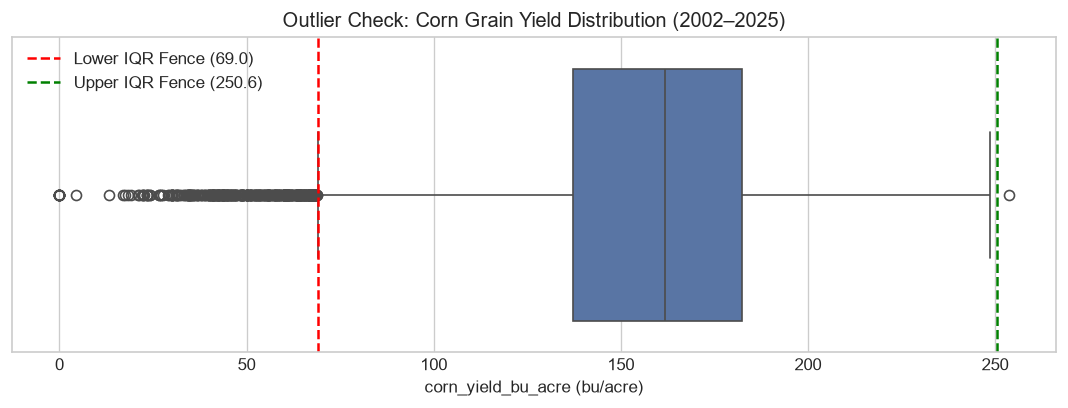

In [7]:
# 4. Outlier check on corn_yield_bu_acre using IQR (retain genuine drought failures)
y_vals = yield_df["corn_yield_bu_acre"]
q1, q3 = y_vals.quantile([0.25, 0.75])
iqr = q3 - q1
low_fence = q1 - 1.5 * iqr
high_fence = q3 + 1.5 * iqr

print(f"Q1 = {q1:.2f}, Q3 = {q3:.2f}, IQR = {iqr:.2f} bu/acre")
print(f"IQR Fences: [{low_fence:.2f}, {high_fence:.2f}] bu/acre")
print(f"Records below lower fence: {(y_vals < low_fence).sum()} (includes {(y_vals == 0).sum()} zero-yield records)")
print(f"Records above upper fence: {(y_vals > high_fence).sum()} (max = {y_vals.max():.2f} bu/acre)")

print("\nSample of lowest yields (kept because they represent real drought/crop failures):")
display(yield_df.nsmallest(10, "corn_yield_bu_acre")[["county_fips", "state", "county", "year", "corn_yield_bu_acre"]])

fig, ax = plt.subplots(figsize=(9, 3.5))
sns.boxplot(x=y_vals, color="#4c72b0", ax=ax)
ax.axvline(low_fence, color="red", linestyle="--", label=f"Lower IQR Fence ({low_fence:.1f})")
ax.axvline(high_fence, color="green", linestyle="--", label=f"Upper IQR Fence ({high_fence:.1f})")
ax.set_title("Outlier Check: Corn Grain Yield Distribution (2002–2025)")
ax.set_xlabel("corn_yield_bu_acre (bu/acre)")
ax.legend()
plt.tight_layout()
plt.show()

All cleaned tables have **zero duplicate keys**. The `9` zero-yield records come from western/central South Dakota counties during severe dry years, so we keep them instead of deleting valid drought observations. Because zero values exist in the target, we use **R², MAE, MSE, and RMSE** (instead of division-by-zero MAPE) during evaluation.

## 4. Dataset Joining

We now build our integrated county-year table step by step starting from `USDA_Yield_Cleaned.csv` (`2002–2025`). Each merge below checks the key columns, displays small samples before and after joining, verifies row counts, and inspects unmatched records.

### Join Example 1: USDA NASS Yield + NOAA Climate (`one_to_one`)
We are combining the yield and NOAA climate data using `county_fips` and `year`. Because each county appears at most once per year in both tables, `validate="one_to_one"` ensures no duplicate rows are created.

In [8]:
def join_preview(left_df, right_df, on_keys, validate_mode, title, left_cols, right_cols):
    '''Merge two tables with indicator=True and print before/after diagnostics.'''
    print("=" * 85)
    print(title)
    print("Join Keys:", on_keys, "| Validation:", validate_mode)
    print("\nLeft table sample (4 rows):")
    display(left_df[left_cols].head(4))
    print("Right table sample (4 rows):")
    display(right_df[right_cols].head(4))

    before_n = len(left_df)
    merged = left_df.merge(right_df, on=on_keys, how="left", validate=validate_mode, indicator=True)
    after_n = len(merged)

    print(f"Row count -> Before: {before_n:,} | After: {after_n:,} | Difference: {after_n - before_n:+d}")
    print("Match counts (_merge):")
    display(merged["_merge"].value_counts().rename_axis("status").to_frame("rows"))

    unmatched = merged[merged["_merge"] != "both"]
    if len(unmatched) > 0:
        print(f"Unmatched left rows: {len(unmatched):,}. Sample:")
        display(unmatched[on_keys].head(4))

    out = merged.drop(columns=["_merge"])
    print("Merged result sample (4 rows):")
    display(out[list(dict.fromkeys(left_cols + right_cols))].head(4))
    return out


# Standardize keys on base yield table
base_df = yield_df.copy()
base_df["county_fips"] = base_df["county_fips"].astype(str).str.zfill(5)
base_df["state_fips"] = base_df["county_fips"].str[:2]
base_df = base_df.rename(columns={"county": "county_name"})

# Exclude noaa_prcp_annual_in (contains post-harvest Oct-Dec rain) from modeling features
noaa_keep = [c for c in noaa_df.columns if c.startswith("noaa_") and c != "noaa_prcp_annual_in"]
noaa_sub = noaa_df[["county_fips", "year"] + noaa_keep].copy()
noaa_sub["county_fips"] = noaa_sub["county_fips"].astype(str).str.zfill(5)

step1_df = join_preview(
    base_df, noaa_sub, ["county_fips", "year"], "one_to_one",
    "Join Example 1: USDA NASS Yield + NOAA Climate",
    ["county_fips", "state", "county_name", "year", "corn_yield_bu_acre"],
    ["county_fips", "year", "noaa_prcp_may_aug_in", "noaa_tmean_may_aug_f", "noaa_tmax_jul_f"],
)

Join Example 1: USDA NASS Yield + NOAA Climate
Join Keys: ['county_fips', 'year'] | Validation: one_to_one

Left table sample (4 rows):


,county_fips,state,county_name,year,corn_yield_bu_acre
0,17001,Illinois,Adams,2002,146.0
1,17001,Illinois,Adams,2003,171.0
2,17001,Illinois,Adams,2004,195.0
3,17001,Illinois,Adams,2005,129.0


Right table sample (4 rows):


,county_fips,year,noaa_prcp_may_aug_in,noaa_tmean_may_aug_f,noaa_tmax_jul_f
0,17001,2002,22.08,71.80,88.9
1,17001,2003,15.35,70.58,85.9
2,17001,2004,20.71,69.35,82.6
3,17001,2005,10.16,72.80,89.2


Row count -> Before: 16,390 | After: 16,390 | Difference: +0
Match counts (_merge):


,rows
status,
both,16390
left_only,0
right_only,0


Merged result sample (4 rows):


,county_fips,state,county_name,year,corn_yield_bu_acre,noaa_prcp_may_aug_in,noaa_tmean_may_aug_f,noaa_tmax_jul_f
0,17001,Illinois,Adams,2002,146.0,22.08,71.80,88.9
1,17001,Illinois,Adams,2003,171.0,15.35,70.58,85.9
2,17001,Illinois,Adams,2004,195.0,20.71,69.35,82.6
3,17001,Illinois,Adams,2005,129.0,10.16,72.80,89.2


### Join Example 2: Yield & Climate + PRISM (`one_to_one`)
Next we join `PRISM_Climate_Cleaned.csv` using `county_fips` and `year`. Remember from Section 2 that `2002–2025` PRISM values are full-year summaries (and `2023` precipitation is missing), so we join them here to inspect the merged table and then drop the annual PRISM columns before growing-season analysis and modeling.

In [9]:
prism_keep = [c for c in prism_df.columns if c.startswith("prism_")]
prism_sub = prism_df[["county_fips", "year"] + prism_keep].copy()
prism_sub["county_fips"] = prism_sub["county_fips"].astype(str).str.zfill(5)

step2_df = join_preview(
    step1_df, prism_sub, ["county_fips", "year"], "one_to_one",
    "Join Example 2: (Yield + NOAA) + PRISM",
    ["county_fips", "state", "year", "corn_yield_bu_acre", "noaa_tmean_may_aug_f"],
    ["county_fips", "year", "prism_ppt_mm", "prism_tmean_c", "prism_tmax_c"],
)

Join Example 2: (Yield + NOAA) + PRISM
Join Keys: ['county_fips', 'year'] | Validation: one_to_one

Left table sample (4 rows):


,county_fips,state,year,corn_yield_bu_acre,noaa_tmean_may_aug_f
0,17001,Illinois,2002,146.0,71.80
1,17001,Illinois,2003,171.0,70.58
2,17001,Illinois,2004,195.0,69.35
3,17001,Illinois,2005,129.0,72.80


Right table sample (4 rows):


,county_fips,year,prism_ppt_mm,prism_tmean_c,prism_tmax_c
0,17001,2002,1151.26,11.81,17.31
1,17001,2003,1013.78,11.01,16.49
2,17001,2004,1064.84,11.35,16.61
3,17001,2005,711.53,12.24,17.72


Row count -> Before: 16,390 | After: 16,390 | Difference: +0
Match counts (_merge):


,rows
status,
both,16390
left_only,0
right_only,0


Merged result sample (4 rows):


,county_fips,state,year,corn_yield_bu_acre,noaa_tmean_may_aug_f,prism_ppt_mm,prism_tmean_c,prism_tmax_c
0,17001,Illinois,2002,146.0,71.80,1151.26,11.81,17.31
1,17001,Illinois,2003,171.0,70.58,1013.78,11.01,16.49
2,17001,Illinois,2004,195.0,69.35,1064.84,11.35,16.61
3,17001,Illinois,2005,129.0,72.80,711.53,12.24,17.72


### Join Example 3: County-Year Dataset + USDA RMA (`one_to_one`)
Now we add pre-harvest crop insurance indicators from `RMA_Cleaned.csv` (`policies_sold`, `net_planted_acres`, `liability_per_planted_acre`, `premium_per_planted_acre`, `subsidy`) using `county_fips` and `year`. Post-harvest insurance columns (`rma_postharvest_*`) are excluded because indemnities happen after harvest and would leak the target. Some low-acreage county-years have no RMA corn policies (`left_only`), which we keep as `NaN` rather than dropping rows.

In [10]:
rma_preharvest = [c for c in rma_df.columns if c.startswith("rma_") and "postharvest" not in c]
rma_sub = rma_df[["county_fips", "year"] + rma_preharvest].copy()
rma_sub["county_fips"] = rma_sub["county_fips"].astype(str).str.zfill(5)

step3_df = join_preview(
    step2_df, rma_sub, ["county_fips", "year"], "one_to_one",
    "Join Example 3: County-Year Data + USDA RMA (Pre-Harvest Only)",
    ["county_fips", "state", "year", "corn_yield_bu_acre"],
    ["county_fips", "year", "rma_policies_sold", "rma_net_planted_acres", "rma_liability_per_planted_acre"],
)

Join Example 3: County-Year Data + USDA RMA (Pre-Harvest Only)
Join Keys: ['county_fips', 'year'] | Validation: one_to_one

Left table sample (4 rows):


,county_fips,state,year,corn_yield_bu_acre
0,17001,Illinois,2002,146.0
1,17001,Illinois,2003,171.0
2,17001,Illinois,2004,195.0
3,17001,Illinois,2005,129.0


Right table sample (4 rows):


,county_fips,year,rma_policies_sold,rma_net_planted_acres,rma_liability_per_planted_acre
0,17001,2002,1047.0,103037.0,217.16
1,17001,2003,1027.0,109830.0,229.09
2,17001,2004,1012.0,109517.0,273.85
3,17001,2005,987.0,118347.0,238.11


Row count -> Before: 16,390 | After: 16,390 | Difference: +0
Match counts (_merge):


,rows
status,
both,16024
left_only,366
right_only,0


Unmatched left rows: 366. Sample:


,county_fips,year
447,17043,2002
448,17043,2003
449,17043,2004
450,17043,2005


Merged result sample (4 rows):


,county_fips,state,year,corn_yield_bu_acre,rma_policies_sold,rma_net_planted_acres,rma_liability_per_planted_acre
0,17001,Illinois,2002,146.0,1047.0,103037.0,217.16
1,17001,Illinois,2003,171.0,1027.0,109830.0,229.09
2,17001,Illinois,2004,195.0,1012.0,109517.0,273.85
3,17001,Illinois,2005,129.0,987.0,118347.0,238.11


### Join Example 4: County-Year Dataset + SoilGrids (`many_to_one`)
SoilGrids is a static county-level dataset (one row per county, no `year` column). First we calculate depth-weighted `0–30 cm` averages (`5/30` for `0–5 cm`, `10/30` for `5–15 cm`, and `15/30` for `15–30 cm`). Then we join on `county_fips` with `validate="many_to_one"`. Because soil changes very slowly over decades, repeating each county's static soil values across all its years (`2002–2025`) is expected and valid.

In [11]:
soil_work = soil_df.copy()
soil_work["county_fips"] = soil_work["county_fips"].astype(str).str.zfill(5)

# Depth-weighted 0-30 cm averages
soil_work["soil_clay_mean_0_30cm"] = (soil_work["clay_0_5cm"]*5 + soil_work["clay_5_15cm"]*10 + soil_work["clay_15_30cm"]*15) / 30.0
soil_work["soil_sand_mean_0_30cm"] = (soil_work["sand_0_5cm"]*5 + soil_work["sand_5_15cm"]*10 + soil_work["sand_15_30cm"]*15) / 30.0
soil_work["soil_silt_mean_0_30cm"] = (soil_work["silt_0_5cm"]*5 + soil_work["silt_5_15cm"]*10 + soil_work["silt_15_30cm"]*15) / 30.0
soil_work["soil_soc_mean_0_30cm"]  = (soil_work["soc_0_5cm"]*5  + soil_work["soc_5_15cm"]*10  + soil_work["soc_15_30cm"]*15) / 30.0
soil_work["soil_ph_mean_0_30cm"]   = (soil_work["phh2o_0_5cm"]*5 + soil_work["phh2o_5_15cm"]*10 + soil_work["phh2o_15_30cm"]*15) / 30.0
soil_work["soil_bdod_mean_0_30cm"] = (soil_work["bdod_0_5cm"]*5 + soil_work["bdod_5_15cm"]*10 + soil_work["bdod_15_30cm"]*15) / 30.0

soil_cols_keep = [
    "county_fips", "intptlat", "intptlon",
    "soil_clay_mean_0_30cm", "soil_sand_mean_0_30cm", "soil_silt_mean_0_30cm",
    "soil_soc_mean_0_30cm", "soil_ph_mean_0_30cm", "soil_bdod_mean_0_30cm"
]
soil_sub = soil_work[soil_cols_keep].rename(columns={"intptlat": "soil_intptlat", "intptlon": "soil_intptlon"})

step4_df = join_preview(
    step3_df, soil_sub, ["county_fips"], "many_to_one",
    "Join Example 4: County-Year Data + SoilGrids (Static County Profile)",
    ["county_fips", "state", "year", "corn_yield_bu_acre"],
    ["county_fips", "soil_soc_mean_0_30cm", "soil_clay_mean_0_30cm", "soil_ph_mean_0_30cm"],
)

Join Example 4: County-Year Data + SoilGrids (Static County Profile)
Join Keys: ['county_fips'] | Validation: many_to_one

Left table sample (4 rows):


,county_fips,state,year,corn_yield_bu_acre
0,17001,Illinois,2002,146.0
1,17001,Illinois,2003,171.0
2,17001,Illinois,2004,195.0
3,17001,Illinois,2005,129.0


Right table sample (4 rows):


,county_fips,soil_soc_mean_0_30cm,soil_clay_mean_0_30cm,soil_ph_mean_0_30cm
0,17001,1.430000,30.656667,6.021667
1,17003,1.645000,24.255000,5.593333
2,17005,1.316667,26.540000,6.158333
3,17007,2.281667,32.656667,6.341667


Row count -> Before: 16,390 | After: 16,390 | Difference: +0
Match counts (_merge):


,rows
status,
both,16390
left_only,0
right_only,0


Merged result sample (4 rows):


,county_fips,state,year,corn_yield_bu_acre,soil_soc_mean_0_30cm,soil_clay_mean_0_30cm,soil_ph_mean_0_30cm
0,17001,Illinois,2002,146.0,1.43,30.656667,6.021667
1,17001,Illinois,2003,171.0,1.43,30.656667,6.021667
2,17001,Illinois,2004,195.0,1.43,30.656667,6.021667
3,17001,Illinois,2005,129.0,1.43,30.656667,6.021667


### Adding State-Level Crop Condition & Progress (`state_fips`, `year`)
Finally, we attach `Crop_Condition_Cleaned.csv` and pre-harvest `Crop_Progress_Cleaned.csv` using `["state_fips", "year"]` (`many_to_one`). These are **state-level** survey averages shared by all counties within the same state and year.

In [12]:
cond_cols = [c for c in cond_df.columns if c.startswith("state_cond_")]
prog_cols = [c for c in prog_df.columns if c.startswith("state_progress_") and "postharvest" not in c]

state_df = cond_df[["state_fips", "year"] + cond_cols].merge(
    prog_df[["state_fips", "year"] + prog_cols],
    on=["state_fips", "year"],
    how="inner",
    validate="one_to_one",
)
state_df["state_fips"] = state_df["state_fips"].astype(str).str.zfill(2)

master_df = step4_df.merge(state_df, on=["state_fips", "year"], how="left", validate="many_to_one")
print(f"Final integrated dataset shape: {master_df.shape} | Duplicate (county_fips, year): {master_df.duplicated(['county_fips', 'year']).sum()}")

Final integrated dataset shape: (16390, 59) | Duplicate (county_fips, year): 0


## 5. Exploratory Data Analysis (EDA)

Here we explore the integrated county-year dataset (`2002–2025`): yield distribution, annual yield trends, state comparisons, climate distributions, correlations, missing values, and boxplots.

,count,mean,std,min,25%,50%,75%,max
corn_yield_bu_acre,16390.0,157.45,36.25,0.00,137.10,161.90,182.50,253.60
noaa_tmean_may_aug_f,16390.0,69.34,3.11,58.00,67.30,69.40,71.43,79.82
noaa_tmax_jul_f,16390.0,85.13,3.87,71.90,82.50,84.90,87.60,98.90
noaa_prcp_may_aug_in,16390.0,16.49,4.59,2.97,13.34,16.36,19.47,39.19
soil_soc_mean_0_30cm,16379.0,2.05,0.55,1.08,1.68,1.93,2.38,5.78
soil_clay_mean_0_30cm,16379.0,29.08,6.77,8.51,25.86,29.68,33.27,56.32
soil_ph_mean_0_30cm,16379.0,6.31,0.46,5.06,6.03,6.26,6.55,7.89
rma_liability_per_planted_acre,16024.0,506.38,228.12,27.62,318.31,506.10,653.33,1457.62
state_cond_rep_good_excellent_mean,16390.0,61.89,17.36,4.86,52.71,64.57,75.14,90.14


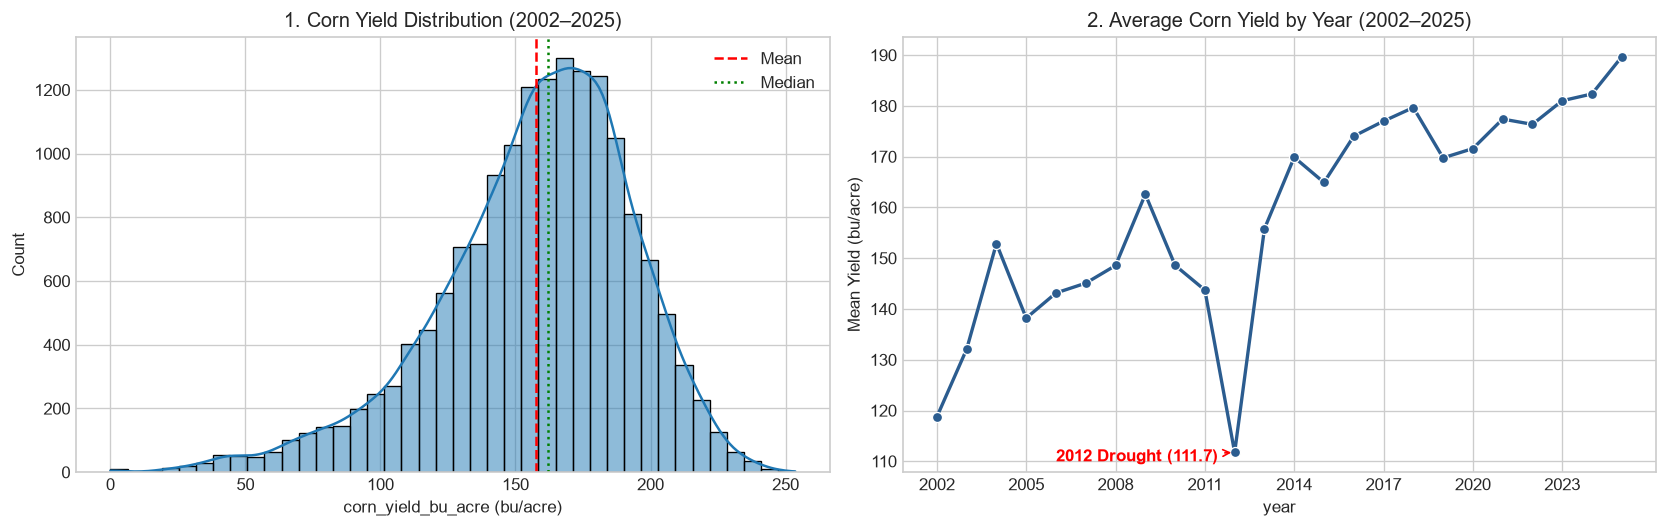

In [13]:
# Summary statistics for main variables
eda_cols = [
    "corn_yield_bu_acre", "noaa_tmean_may_aug_f", "noaa_tmax_jul_f",
    "noaa_prcp_may_aug_in", "soil_soc_mean_0_30cm", "soil_clay_mean_0_30cm",
    "soil_ph_mean_0_30cm", "rma_liability_per_planted_acre", "state_cond_rep_good_excellent_mean"
]
display(master_df[eda_cols].describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]].round(2))

# 1. Yield Distribution & 2. Yield by Year
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(master_df["corn_yield_bu_acre"], bins=40, kde=True, color="#1f78b4", ax=ax1)
ax1.axvline(master_df["corn_yield_bu_acre"].mean(), color="red", linestyle="--", label="Mean")
ax1.axvline(master_df["corn_yield_bu_acre"].median(), color="green", linestyle=":", label="Median")
ax1.set_title("1. Corn Yield Distribution (2002–2025)")
ax1.set_xlabel("corn_yield_bu_acre (bu/acre)")
ax1.legend()

annual_y = master_df.groupby("year")["corn_yield_bu_acre"].mean().reset_index()
sns.lineplot(data=annual_y, x="year", y="corn_yield_bu_acre", marker="o", color="#2b5c8f", lw=2, ax=ax2)
d12_y = annual_y.loc[annual_y["year"] == 2012, "corn_yield_bu_acre"].values[0]
ax2.annotate(f"2012 Drought ({d12_y:.1f})", xy=(2012, d12_y), xytext=(2006, 110),
             arrowprops=dict(arrowstyle="->", color="red"), color="red", fontweight="bold")
ax2.set_title("2. Average Corn Yield by Year (2002–2025)")
ax2.set_ylabel("Mean Yield (bu/acre)")
ax2.set_xticks(range(2002, 2026, 3))
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eda_yield_dist_and_year.png", dpi=130)
plt.show()

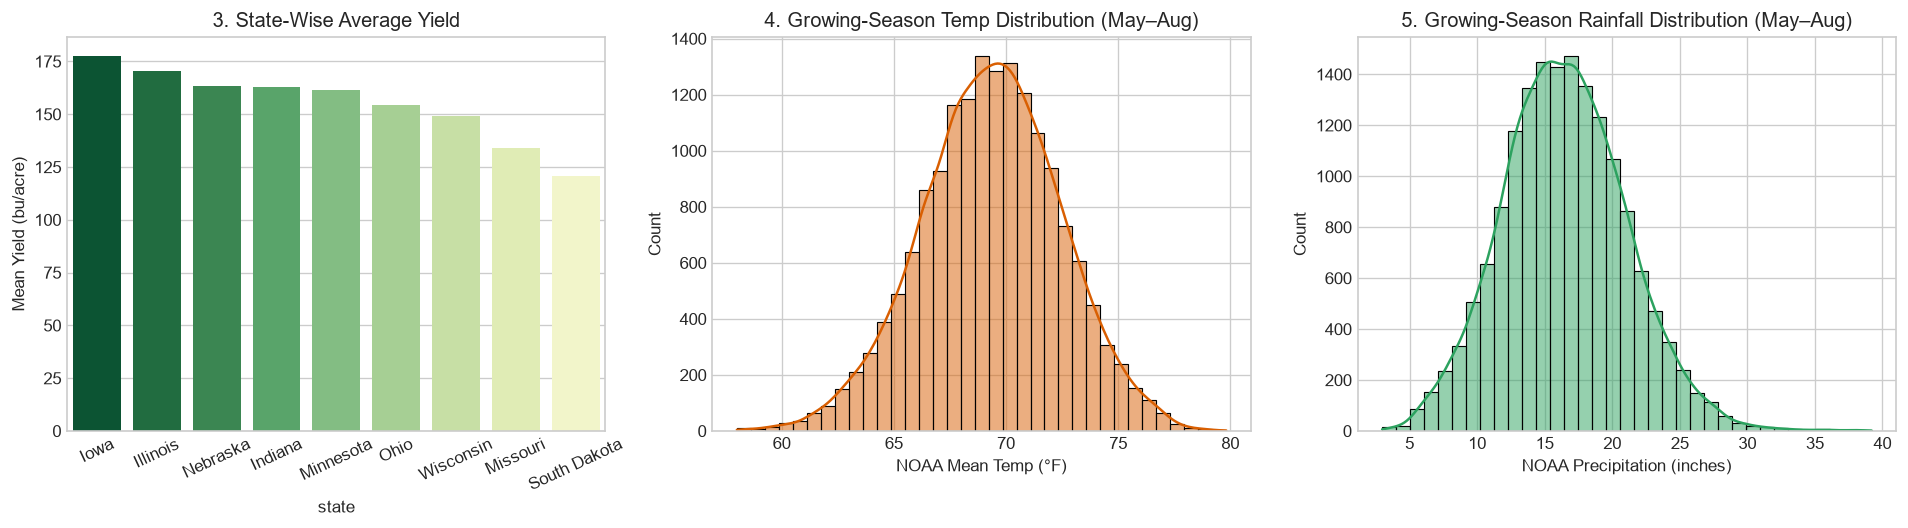

In [14]:
# 3. State-wise Average Yield, 4. Temperature Distribution, 5. Rainfall Distribution
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

st_mean = master_df.groupby("state")["corn_yield_bu_acre"].mean().sort_values(ascending=False)
sns.barplot(x=st_mean.index, y=st_mean.values, hue=st_mean.index, palette="YlGn_r", legend=False, ax=axes[0])
axes[0].set_title("3. State-Wise Average Yield")
axes[0].set_ylabel("Mean Yield (bu/acre)")
axes[0].tick_params(axis="x", rotation=25)

sns.histplot(master_df["noaa_tmean_may_aug_f"], bins=35, kde=True, color="#d95f02", ax=axes[1])
axes[1].set_title("4. Growing-Season Temp Distribution (May–Aug)")
axes[1].set_xlabel("NOAA Mean Temp (°F)")

sns.histplot(master_df["noaa_prcp_may_aug_in"], bins=35, kde=True, color="#2ca25f", ax=axes[2])
axes[2].set_title("5. Growing-Season Rainfall Distribution (May–Aug)")
axes[2].set_xlabel("NOAA Precipitation (inches)")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eda_state_temp_rain.png", dpi=130)
plt.show()

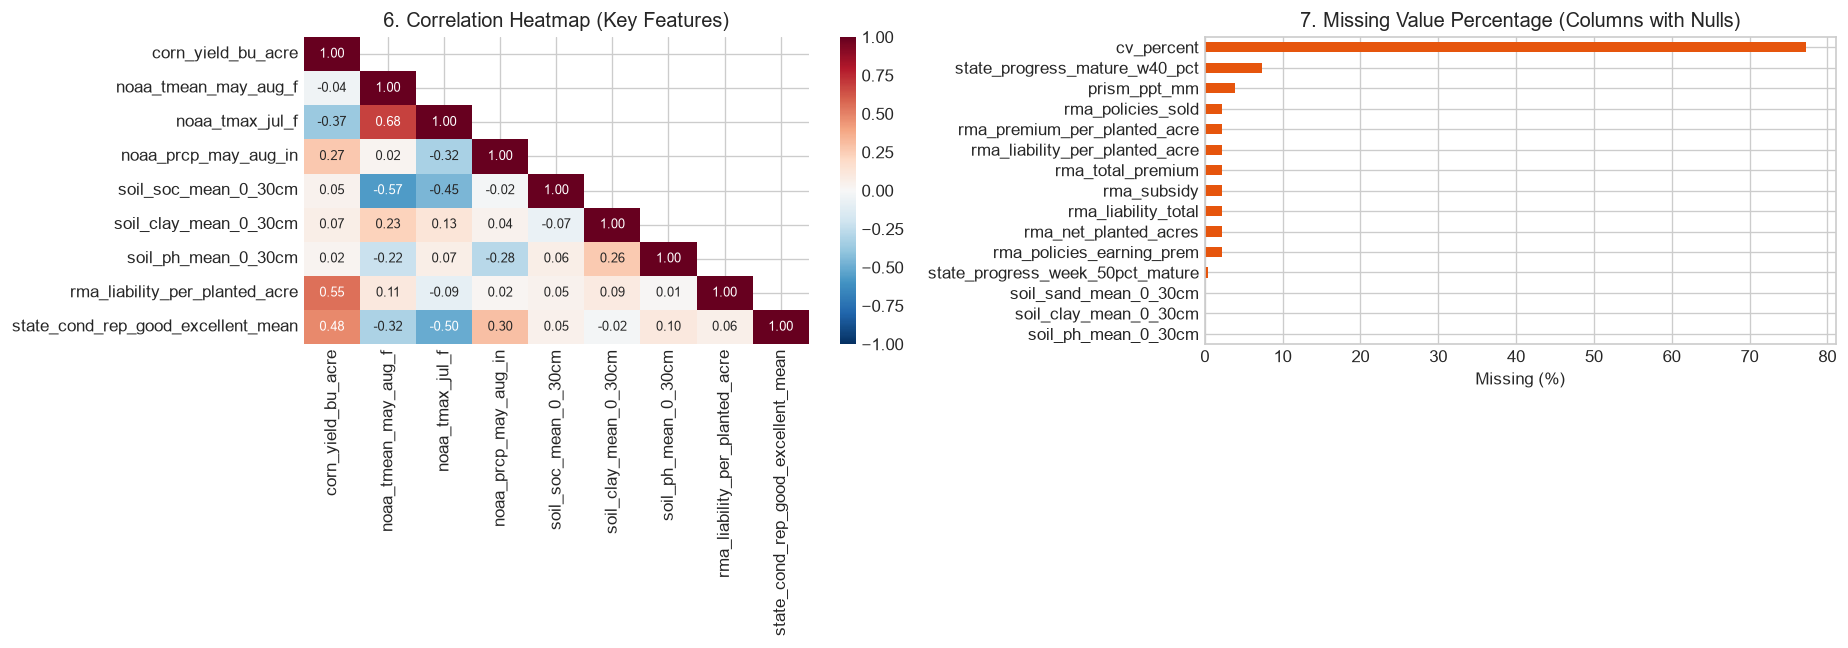

In [15]:
# 6. Correlation Heatmap & 7. Missing-Value Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.5, 5.5))

corr_mat = master_df[eda_cols].corr()
mask = np.triu(np.ones_like(corr_mat, dtype=bool), k=1)
sns.heatmap(corr_mat, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot_kws={"size": 8}, ax=ax1)
ax1.set_title("6. Correlation Heatmap (Key Features)")

miss_pct = (master_df.isna().mean() * 100)
miss_pct = miss_pct[miss_pct > 0].sort_values(ascending=True)
miss_pct.tail(15).plot(kind="barh", color="#e6550d", ax=ax2)
ax2.set_title("7. Missing Value Percentage (Columns with Nulls)")
ax2.set_xlabel("Missing (%)")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eda_corr_and_missing.png", dpi=130)
plt.show()

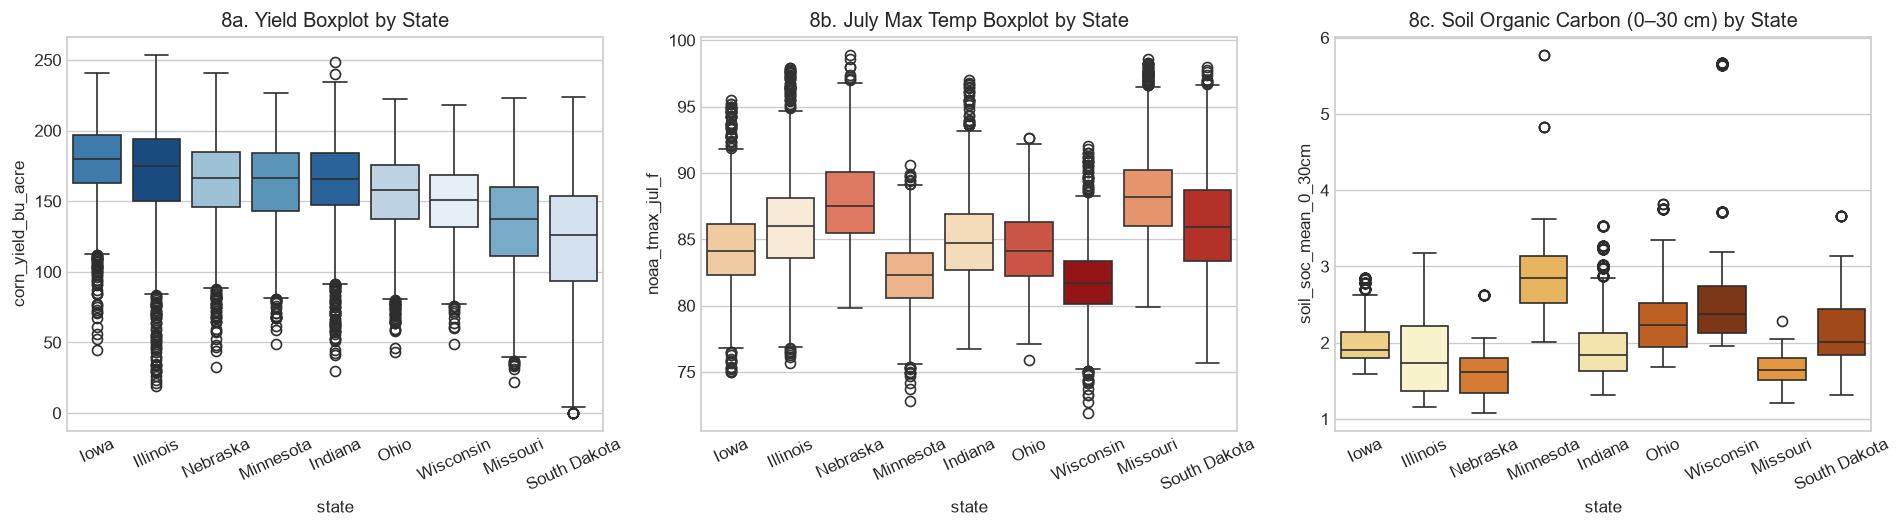

In [16]:
# 8. Boxplots for Important Variables
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

order_st = master_df.groupby("state")["corn_yield_bu_acre"].median().sort_values(ascending=False).index
sns.boxplot(data=master_df, x="state", y="corn_yield_bu_acre", order=order_st, hue="state", palette="Blues_r", legend=False, ax=axes[0])
axes[0].set_title("8a. Yield Boxplot by State")
axes[0].tick_params(axis="x", rotation=25)

sns.boxplot(data=master_df, x="state", y="noaa_tmax_jul_f", order=order_st, hue="state", palette="OrRd", legend=False, ax=axes[1])
axes[1].set_title("8b. July Max Temp Boxplot by State")
axes[1].tick_params(axis="x", rotation=25)

sns.boxplot(data=master_df, x="state", y="soil_soc_mean_0_30cm", order=order_st, hue="state", palette="YlOrBr", legend=False, ax=axes[2])
axes[2].set_title("8c. Soil Organic Carbon (0–30 cm) by State")
axes[2].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eda_boxplots.png", dpi=130)
plt.show()

**What the EDA charts show:**  
Yield averages rise gradually over time due to improved hybrids and farming practices, interrupted sharply by the `2012` Midwest drought. Central states like Iowa and Illinois have higher median yields and cooler July temperatures than southern or western fringe states like Missouri and South Dakota. Most columns are complete; `cv_percent` is missing in most NASS rows, `prism_ppt_mm` is missing in `2023`, and `rma_*` columns have small gaps where no policies were sold.

## 6. Climate and Agricultural Analysis

To study how weather affects maize production, we use **monthly NOAA growing-season variables** (`May–August` and `July–August`), not the full-year PRISM summaries. Remember that correlation and group averages show statistical associations and do not prove causation by themselves.

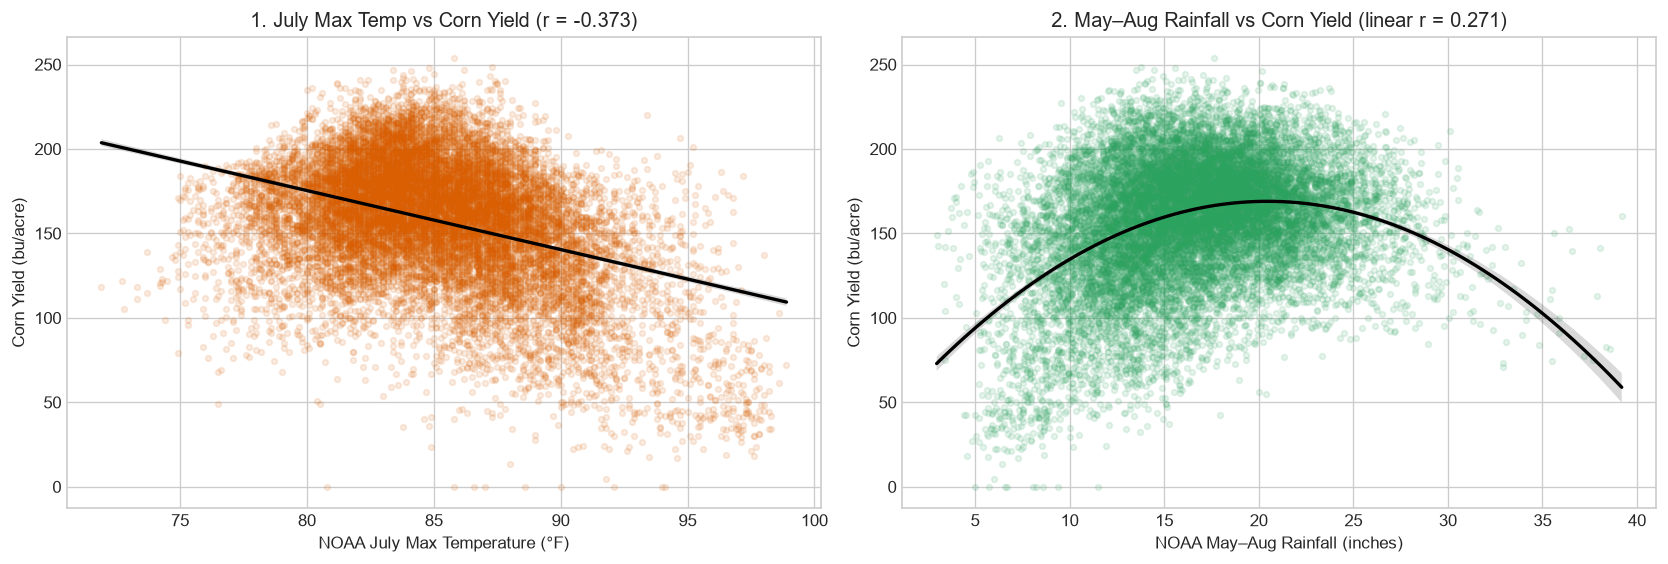

In [17]:
# 1. Temperature vs Yield & 2. Rainfall vs Yield scatter plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))

r_temp, _ = stats.pearsonr(master_df["noaa_tmax_jul_f"], master_df["corn_yield_bu_acre"])
sns.regplot(data=master_df, x="noaa_tmax_jul_f", y="corn_yield_bu_acre", ax=ax1,
            scatter_kws={"alpha": 0.12, "s": 12, "color": "#d95f02"}, line_kws={"color": "black", "lw": 2})
ax1.set_title(f"1. July Max Temp vs Corn Yield (r = {r_temp:.3f})")
ax1.set_xlabel("NOAA July Max Temperature (°F)")
ax1.set_ylabel("Corn Yield (bu/acre)")

r_rain, _ = stats.pearsonr(master_df["noaa_prcp_may_aug_in"], master_df["corn_yield_bu_acre"])
sns.regplot(data=master_df, x="noaa_prcp_may_aug_in", y="corn_yield_bu_acre", order=2, ax=ax2,
            scatter_kws={"alpha": 0.12, "s": 12, "color": "#2ca25f"}, line_kws={"color": "black", "lw": 2})
ax2.set_title(f"2. May–Aug Rainfall vs Corn Yield (linear r = {r_rain:.3f})")
ax2.set_xlabel("NOAA May–Aug Rainfall (inches)")
ax2.set_ylabel("Corn Yield (bu/acre)")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "climate_temp_rain_scatter.png", dpi=130)
plt.show()

**What these scatter plots tell us:**  
Higher July maximum temperatures (during pollination/silking) show a clear negative relationship with yield. May–August rainfall shows a curved relationship: very dry summers (`< 12 inches`) hurt yield strongly, moderate-to-optimal rainfall (`16–20 inches`) supports higher yields, and very heavy rainfall (`> 24 inches`) flattens or slightly lowers yields.

,count,mean,std
heat_group,,,
Cool (<85°F),7619,167.70,29.70
Moderate (85–90°F),6713,158.20,33.19
Hot (90–95°F),1772,122.06,36.75
Extreme (>=95°F),286,85.85,43.77


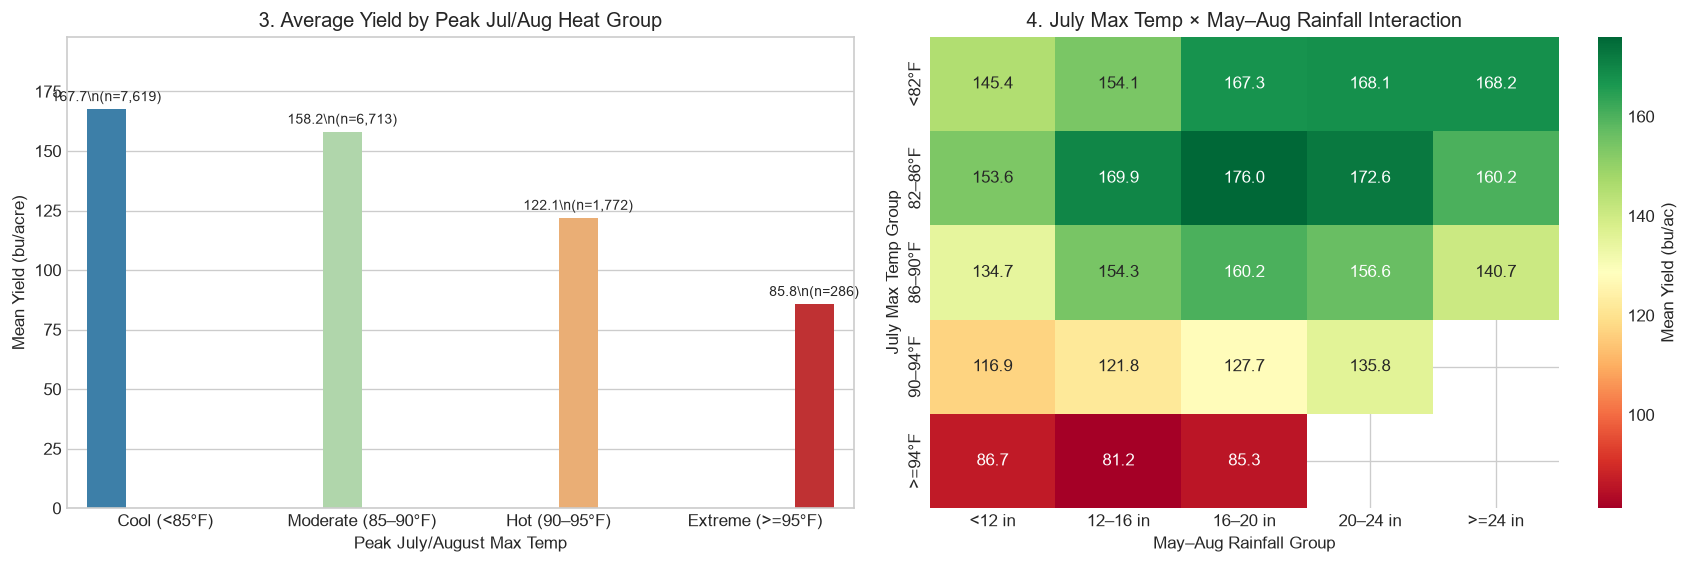

In [18]:
# 3. Heat Stress Groups vs Average Yield & 4. Temperature x Rainfall Interaction Heatmap
master_df["heat_group"] = pd.cut(
    master_df["noaa_heat_stress_max_f"],
    bins=[0, 85, 90, 95, 130],
    labels=["Cool (<85°F)", "Moderate (85–90°F)", "Hot (90–95°F)", "Extreme (>=95°F)"],
    right=False,
)
master_df["rain_group"] = pd.cut(
    master_df["noaa_prcp_may_aug_in"],
    bins=[0, 12, 16, 20, 24, 100],
    labels=["<12 in", "12–16 in", "16–20 in", "20–24 in", ">=24 in"],
    right=False,
)
master_df["jul_tmax_group"] = pd.cut(
    master_df["noaa_tmax_jul_f"],
    bins=[0, 82, 86, 90, 94, 130],
    labels=["<82°F", "82–86°F", "86–90°F", "90–94°F", ">=94°F"],
    right=False,
)

heat_summary = master_df.groupby("heat_group", observed=False)["corn_yield_bu_acre"].agg(["count", "mean", "std"]).round(2)
display(heat_summary)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 4.8))

sns.barplot(x=heat_summary.index, y=heat_summary["mean"], hue=heat_summary.index,
            palette=["#2b83ba", "#abdda4", "#fdae61", "#d7191c"], legend=False, ax=ax1)
ax1.set_title("3. Average Yield by Peak Jul/Aug Heat Group")
ax1.set_ylabel("Mean Yield (bu/acre)")
ax1.set_xlabel("Peak July/August Max Temp")
ax1.set_ylim(0, heat_summary["mean"].max() * 1.18)
for bar, (_, r) in zip(ax1.patches, heat_summary.iterrows()):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2, f"{r['mean']:.1f}\\n(n={int(r['count']):,})",
             ha="center", va="bottom", fontsize=8.5)

piv = master_df.pivot_table(index="jul_tmax_group", columns="rain_group", values="corn_yield_bu_acre", aggfunc="mean", observed=False)
piv_n = master_df.pivot_table(index="jul_tmax_group", columns="rain_group", values="corn_yield_bu_acre", aggfunc="count", observed=False)
piv_masked = piv.where(piv_n >= 5)
sns.heatmap(piv_masked, annot=True, fmt=".1f", cmap="RdYlGn", ax=ax2, cbar_kws={"label": "Mean Yield (bu/ac)"})
ax2.set_title("4. July Max Temp × May–Aug Rainfall Interaction")
ax2.set_xlabel("May–Aug Rainfall Group")
ax2.set_ylabel("July Max Temp Group")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "climate_heat_groups_and_interaction.png", dpi=130)
plt.show()

**What the heat-group and interaction plots tell us:**  
Average yield drops steeply once peak July/August maximum temperature exceeds `90°F`, and falls sharpest in the `>=95°F` group. The heatmap shows that low rainfall combined with extreme heat produces the lowest yields, while adequate moisture helps cushion moderate summer warmth.

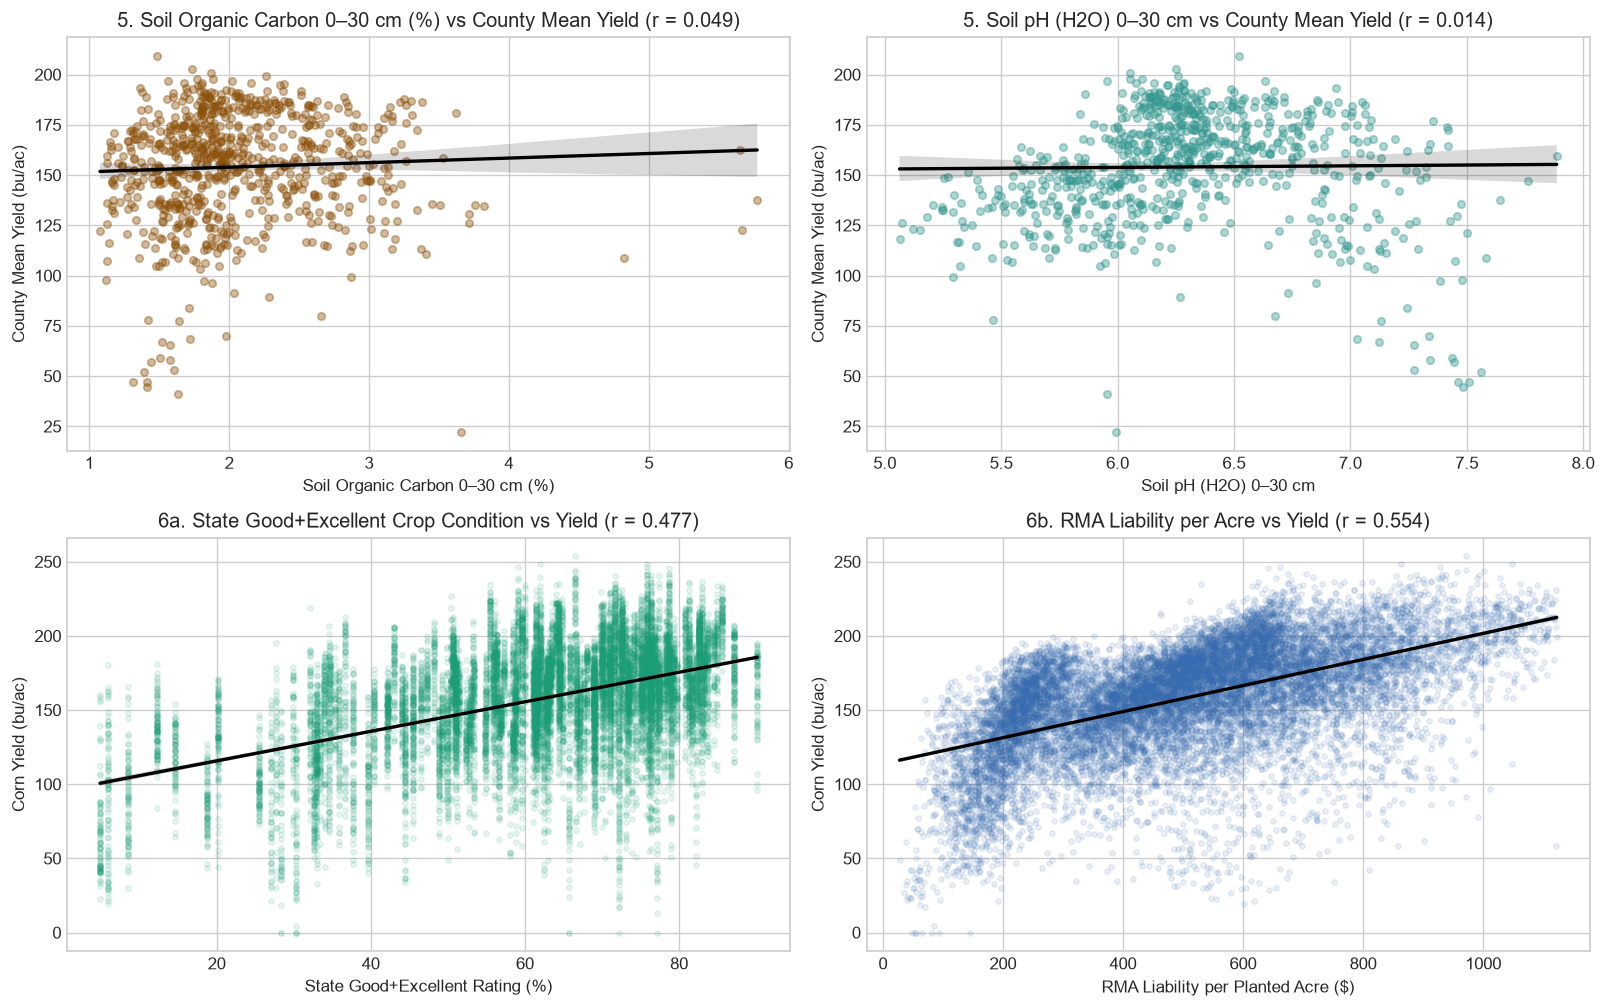

In [19]:
# 5. Soil Properties vs Yield & 6. Agricultural / State Indicators vs Yield
county_soil = master_df.groupby("county_fips").agg(
    mean_yield=("corn_yield_bu_acre", "mean"),
    soc=("soil_soc_mean_0_30cm", "first"),
    ph=("soil_ph_mean_0_30cm", "first"),
    clay=("soil_clay_mean_0_30cm", "first"),
).dropna()

fig, axes = plt.subplots(2, 2, figsize=(13.5, 8.5))

for ax, col, label, colhex in [
    (axes[0, 0], "soc", "Soil Organic Carbon 0–30 cm (%)", "#8c510a"),
    (axes[0, 1], "ph", "Soil pH (H2O) 0–30 cm", "#35978f"),
]:
    r_val, _ = stats.pearsonr(county_soil[col], county_soil["mean_yield"])
    sns.regplot(data=county_soil, x=col, y="mean_yield", ax=ax,
                scatter_kws={"alpha": 0.4, "s": 20, "color": colhex}, line_kws={"color": "black", "lw": 2})
    ax.set_title(f"5. {label} vs County Mean Yield (r = {r_val:.3f})")
    ax.set_xlabel(label)
    ax.set_ylabel("County Mean Yield (bu/ac)")

sub_cond = master_df[["state_cond_rep_good_excellent_mean", "corn_yield_bu_acre"]].dropna()
r_cond, _ = stats.pearsonr(sub_cond["state_cond_rep_good_excellent_mean"], sub_cond["corn_yield_bu_acre"])
sns.regplot(data=sub_cond, x="state_cond_rep_good_excellent_mean", y="corn_yield_bu_acre", ax=axes[1, 0],
            scatter_kws={"alpha": 0.1, "s": 10, "color": "#1b9e77"}, line_kws={"color": "black", "lw": 2})
axes[1, 0].set_title(f"6a. State Good+Excellent Crop Condition vs Yield (r = {r_cond:.3f})")
axes[1, 0].set_xlabel("State Good+Excellent Rating (%)")
axes[1, 0].set_ylabel("Corn Yield (bu/ac)")

sub_rma = master_df[["rma_liability_per_planted_acre", "corn_yield_bu_acre"]].dropna()
sub_rma_trim = sub_rma[sub_rma["rma_liability_per_planted_acre"] <= sub_rma["rma_liability_per_planted_acre"].quantile(0.995)]
r_rma, _ = stats.pearsonr(sub_rma["rma_liability_per_planted_acre"], sub_rma["corn_yield_bu_acre"])
sns.regplot(data=sub_rma_trim, x="rma_liability_per_planted_acre", y="corn_yield_bu_acre", ax=axes[1, 1],
            scatter_kws={"alpha": 0.1, "s": 10, "color": "#386cb0"}, line_kws={"color": "black", "lw": 2})
axes[1, 1].set_title(f"6b. RMA Liability per Acre vs Yield (r = {r_rma:.3f})")
axes[1, 1].set_xlabel("RMA Liability per Planted Acre ($)")
axes[1, 1].set_ylabel("Corn Yield (bu/ac)")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "soil_and_agri_vs_yield.png", dpi=130)
plt.show()

**What the soil and agricultural plots tell us:**  
Counties with higher soil organic carbon (`SOC`) generally achieve higher long-term yields because organic matter improves nutrient supply and water retention. State-level Good+Excellent condition ratings and pre-harvest RMA insurance liability per acre also correlate positively with yield, though insurance liability also reflects rising crop values and technology trends over time.

## 7. Statistical Analysis (Training Data: 2002–2020 Only)

Before training ML models, we prepare our features and run statistical tests strictly on the **training period (`2002–2020`)** so test observations (`2021–2025`) never influence feature screening:
- **Pearson correlation ($r$):** Measures linear association.
- **Spearman correlation ($\\rho$):** Measures monotonic rank association (captures curved relationships).
- **F-statistic (`f_regression`):** Tests whether a predictor has a statistically significant linear relationship with yield (`H0`: slope = `0`). Larger `F` and smaller `p-value` (`< 0.05`) indicate stronger linear signal.
- **OLS Nested Regression F-Test:** Tests whether adding growing-season climate features significantly improves yield fit above soil, pre-harvest insurance, and year trend alone.

In [20]:
# Build engineered climate ratios and strictly causal prior-year yield lags (t-1, t-2, t-3)
model_df = master_df.copy().sort_values(["county_fips", "year"]).reset_index(drop=True)

model_df["diurnal_range_may_aug_f"] = model_df["noaa_tmax_may_aug_f"] - model_df["noaa_tmin_may_aug_f"]
model_df["prcp_jul_aug_in"] = model_df["noaa_prcp_jul_in"] + model_df["noaa_prcp_aug_in"]
model_df["heat_drought_index_jul"] = model_df["noaa_tmax_jul_f"] / (model_df["noaa_prcp_jul_in"] + 1.0)
model_df["rma_missing_flag"] = model_df["rma_policies_sold"].isna().astype(int)

# Strictly causal calendar-year yield lags per county (uses past years only)
lag_lookup = model_df.set_index(["county_fips", "year"])["corn_yield_bu_acre"]
for k in [1, 2, 3]:
    model_df[f"yield_lag_{k}yr"] = [
        lag_lookup.get((fips, yr - k), np.nan)
        for fips, yr in zip(model_df["county_fips"], model_df["year"])
    ]
model_df["yield_past3yr_mean"] = model_df[["yield_lag_1yr", "yield_lag_2yr", "yield_lag_3yr"]].mean(axis=1)

# Define training mask (2002-2020) for leak-free statistical tests
train_stat_df = model_df[model_df["year"] <= 2020].copy()

stat_cols = [
    "yield_lag_1yr", "yield_past3yr_mean", "year",
    "state_cond_rep_good_excellent_mean", "noaa_tmax_jul_f", "noaa_heat_stress_max_f",
    "noaa_tmean_may_aug_f", "heat_drought_index_jul", "noaa_prcp_may_aug_in",
    "prcp_jul_aug_in", "soil_soc_mean_0_30cm", "soil_ph_mean_0_30cm",
    "soil_clay_mean_0_30cm", "rma_liability_per_planted_acre",
]

corr_rows = []
for col in stat_cols:
    sub = train_stat_df[[col, "corn_yield_bu_acre"]].dropna()
    rp, pp = stats.pearsonr(sub[col], sub["corn_yield_bu_acre"])
    rs, ps = stats.spearmanr(sub[col], sub["corn_yield_bu_acre"])
    corr_rows.append({
        "Feature": col,
        "N": len(sub),
        "Pearson_r": round(rp, 4),
        "Pearson_p": f"{pp:.2e}",
        "Spearman_rho": round(rs, 4),
        "Spearman_p": f"{ps:.2e}",
    })

display(pd.DataFrame(corr_rows).sort_values("Pearson_r", key=lambda s: s.abs(), ascending=False))

,Feature,N,Pearson_r,Pearson_p,Spearman_rho,Spearman_p
1,yield_past3yr_mean,12508,0.6549,0.00e+00,0.6585,0.00e+00
0,yield_lag_1yr,11958,0.6335,0.00e+00,0.6473,0.00e+00
3,state_cond_rep_good_excellent_mean,13397,0.4970,0.00e+00,0.4550,0.00e+00
13,rma_liability_per_planted_acre,13079,0.4565,0.00e+00,0.4970,0.00e+00
5,noaa_heat_stress_max_f,13397,-0.4007,0.00e+00,-0.3439,0.00e+00
4,noaa_tmax_jul_f,13397,-0.3924,0.00e+00,-0.3271,0.00e+00
2,year,13397,0.3909,0.00e+00,0.4092,0.00e+00
7,heat_drought_index_jul,13397,-0.3798,0.00e+00,-0.3099,3.81e-296
8,noaa_prcp_may_aug_in,13397,0.3258,0.00e+00,0.3033,5.64e-283
9,prcp_jul_aug_in,13397,0.3118,5.81e-300,0.3079,5.02e-292


,Feature,F_Statistic,p_value
0,yield_past3yr_mean,7697.74,0.00e+00
1,yield_lag_1yr,6295.72,0.00e+00
2,state_cond_rep_good_excellent_mean,4394.37,0.00e+00
3,rma_liability_per_planted_acre,3324.76,0.00e+00
4,noaa_heat_stress_max_f,2562.49,0.00e+00
5,noaa_tmax_jul_f,2438.41,0.00e+00
6,year,2415.51,0.00e+00
7,heat_drought_index_jul,2258.49,0.00e+00
8,noaa_prcp_may_aug_in,1590.98,0.00e+00
9,prcp_jul_aug_in,1442.96,5.81e-300


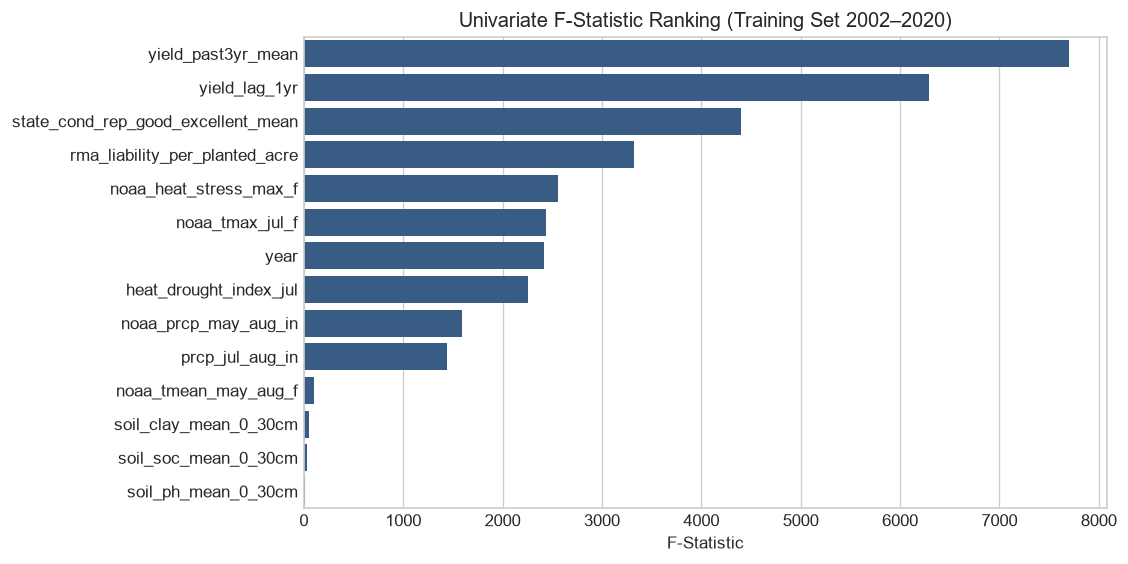

In [21]:
# Univariate F-test screening using sklearn.feature_selection.f_regression (training data only)
screen_imp = SimpleImputer(strategy="median")
X_screen = screen_imp.fit_transform(train_stat_df[stat_cols])
y_screen = train_stat_df["corn_yield_bu_acre"].values

f_scores, p_vals = f_regression(X_screen, y_screen)
f_df = pd.DataFrame({
    "Feature": stat_cols,
    "F_Statistic": np.round(f_scores, 2),
    "p_value": [f"{p:.2e}" for p in p_vals],
}).sort_values("F_Statistic", ascending=False).reset_index(drop=True)
display(f_df)

fig, ax = plt.subplots(figsize=(9.5, 4.8))
sns.barplot(data=f_df, y="Feature", x="F_Statistic", color="#2b5c8f", ax=ax)
ax.set_title("Univariate F-Statistic Ranking (Training Set 2002–2020)")
ax.set_xlabel("F-Statistic")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "stat_f_regression.png", dpi=130)
plt.show()

In [22]:
# Regression F-test: Compare Base Model (Year + Soil + RMA) vs Expanded Model (+ Growing-Season Climate)
base_cols = ["year", "soil_soc_mean_0_30cm", "soil_clay_mean_0_30cm", "soil_ph_mean_0_30cm", "rma_liability_per_planted_acre"]
clim_cols = ["noaa_tmean_may_aug_f", "noaa_tmax_jul_f", "noaa_prcp_may_aug_in", "prcp_jul_aug_in", "heat_drought_index_jul"]

ols_data = train_stat_df[["corn_yield_bu_acre"] + base_cols + clim_cols].dropna()
ols_base = sm.OLS(ols_data["corn_yield_bu_acre"], sm.add_constant(ols_data[base_cols])).fit()
ols_full = sm.OLS(ols_data["corn_yield_bu_acre"], sm.add_constant(ols_data[base_cols + clim_cols])).fit()

f_nested, p_nested, df_diff = ols_full.compare_f_test(ols_base)

print(f"Base Model (Year + Soil + RMA)      -> R² = {ols_base.rsquared:.4f}, Overall F = {ols_base.fvalue:.2f} (p = {ols_base.f_pvalue:.2e})")
print(f"Expanded Model (+ Climate Features) -> R² = {ols_full.rsquared:.4f}, Overall F = {ols_full.fvalue:.2f} (p = {ols_full.f_pvalue:.2e})")
print(f"Partial F-Test (Climate Group Added)-> F({int(df_diff)}, {int(ols_full.df_resid)}) = {f_nested:.2f}, p = {p_nested:.2e}")

Base Model (Year + Soil + RMA)      -> R² = 0.2324, Overall F = 790.82 (p = 0.00e+00)
Expanded Model (+ Climate Features) -> R² = 0.4598, Overall F = 1111.39 (p = 0.00e+00)
Partial F-Test (Climate Group Added)-> F(5, 13058) = 1099.46, p = 0.00e+00


**What the statistical tests show:**  
Both `f_regression` and the nested OLS `F-test` yield very large `F`-statistics with `p < 0.001`, showing that adding growing-season climate and heat indicators significantly improves explanatory power over soil, insurance, and year trends alone. Remember that statistical significance shows predictive association in observed data, not proof of causation.

## 8. Machine Learning Model Building

### A. Dependent and Independent Variables
- **Dependent Variable ($y$):** `corn_yield_bu_acre` — the continuous county yield we want to predict.
- **Independent Variables ($X$):** Pre-harvest features from weather (`NOAA May–Sep`), soil (`SoilGrids 0–30 cm`), crop insurance (`RMA`), state crop condition/progress surveys, `year`, `state`, and strictly prior-year county yields (`yield_lag_1yr`, `yield_lag_2yr`, `yield_lag_3yr`, `yield_past3yr_mean`).  
Post-harvest columns (`rma_postharvest_*`, `state_progress_postharvest_*`, `noaa_prcp_annual_in`) and annual `prism_*` summaries are excluded.

In [23]:
# Define feature columns clearly by domain
numeric_features = [
    # Trend
    "year",
    # NOAA Growing-Season Climate & Heat Stress (May-Sep)
    "noaa_prcp_may_in", "noaa_prcp_jun_in", "noaa_prcp_jul_in", "noaa_prcp_aug_in", "noaa_prcp_sep_in",
    "noaa_prcp_may_aug_in", "noaa_prcp_may_sep_in",
    "noaa_tmean_may_aug_f", "noaa_tmax_jul_f", "noaa_tmax_aug_f",
    "noaa_tmax_may_aug_f", "noaa_tmin_may_aug_f", "noaa_heat_stress_max_f",
    "diurnal_range_may_aug_f", "prcp_jul_aug_in", "heat_drought_index_jul",
    # ISRIC SoilGrids (Static 0-30 cm county profile)
    "soil_intptlat", "soil_intptlon",
    "soil_clay_mean_0_30cm", "soil_sand_mean_0_30cm", "soil_silt_mean_0_30cm",
    "soil_soc_mean_0_30cm", "soil_ph_mean_0_30cm", "soil_bdod_mean_0_30cm",
    # Pre-Harvest RMA Insurance & State Crop Surveys
    "rma_policies_sold", "rma_net_planted_acres", "rma_liability_per_planted_acre",
    "rma_premium_per_planted_acre", "rma_subsidy", "rma_missing_flag",
    "state_cond_good_excellent_mean", "state_cond_poor_very_poor_mean",
    "state_cond_rep_good_excellent_mean", "state_progress_planted_w20_pct",
    "state_progress_silking_w30_pct", "state_progress_dough_w34_pct",
    # Strictly Causal Historical Yield Lags (past years only)
    "yield_lag_1yr", "yield_lag_2yr", "yield_lag_3yr", "yield_past3yr_mean",
]
categorical_features = ["state"]
feature_columns = numeric_features + categorical_features

target = "corn_yield_bu_acre"
X = model_df[feature_columns].copy()
y = model_df[target].copy()

print(f"X shape: {X.shape} ({len(numeric_features)} numeric + {len(categorical_features)} categorical)")
print(f"y shape: {y.shape}")
print("Independent feature columns:")
print(feature_columns)

X shape: (16390, 42) (41 numeric + 1 categorical)
y shape: (16390,)
Independent feature columns:
['year', 'noaa_prcp_may_in', 'noaa_prcp_jun_in', 'noaa_prcp_jul_in', 'noaa_prcp_aug_in', 'noaa_prcp_sep_in', 'noaa_prcp_may_aug_in', 'noaa_prcp_may_sep_in', 'noaa_tmean_may_aug_f', 'noaa_tmax_jul_f', 'noaa_tmax_aug_f', 'noaa_tmax_may_aug_f', 'noaa_tmin_may_aug_f', 'noaa_heat_stress_max_f', 'diurnal_range_may_aug_f', 'prcp_jul_aug_in', 'heat_drought_index_jul', 'soil_intptlat', 'soil_intptlon', 'soil_clay_mean_0_30cm', 'soil_sand_mean_0_30cm', 'soil_silt_mean_0_30cm', 'soil_soc_mean_0_30cm', 'soil_ph_mean_0_30cm', 'soil_bdod_mean_0_30cm', 'rma_policies_sold', 'rma_net_planted_acres', 'rma_liability_per_planted_acre', 'rma_premium_per_planted_acre', 'rma_subsidy', 'rma_missing_flag', 'state_cond_good_excellent_mean', 'state_cond_poor_very_poor_mean', 'state_cond_rep_good_excellent_mean', 'state_progress_planted_w20_pct', 'state_progress_silking_w30_pct', 'state_progress_dough_w34_pct', 'yield

### B. Chronological Train-Test Split (2002–2020 vs. 2021–2025)
To mirror real-world forecasting, we train on past years (**2002–2020**) and test on later unseen years (**2021–2025**). Randomly mixing past and future years would leak regional weather patterns from test years into training.

In [24]:
print("Available years in historical dataset:", sorted(model_df["year"].unique()))

train_mask = model_df["year"] <= 2020
test_mask = model_df["year"] >= 2021

X_train = X.loc[train_mask].copy()
y_train = y.loc[train_mask].copy()
X_test  = X.loc[test_mask].copy()
y_test  = y.loc[test_mask].copy()

print(f"Training period : {model_df.loc[train_mask, 'year'].min()}–{model_df.loc[train_mask, 'year'].max()}")
print(f"Testing period  : {model_df.loc[test_mask, 'year'].min()}–{model_df.loc[test_mask, 'year'].max()}")
print(f"X_train shape   : {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_test shape    : {X_test.shape}  | y_test shape : {y_test.shape}")

Available years in historical dataset: [np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Training period : 2002–2020
Testing period  : 2021–2025
X_train shape   : (13397, 42) | y_train shape: (13397,)
X_test shape    : (2993, 42)  | y_test shape : (2993,)


### C. Preprocessing Pipeline (Fitted on Training Data Only)
We use Scikit-learn `ColumnTransformer` and `Pipeline`:
- Numeric features: `SimpleImputer(strategy="median")` (plus `StandardScaler()` for linear models that are sensitive to feature scale).
- Categorical feature (`state`): `OneHotEncoder(handle_unknown="ignore")`.  
Because every model runs inside a `Pipeline` fitted on `X_train`, test data statistics never touch imputation or scaling.

In [25]:
def make_preprocessor(scale_numeric=False):
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        num_steps.append(("scaler", StandardScaler()))
    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", Pipeline(num_steps), numeric_features),
        ("cat", cat_pipe, categorical_features),
    ])

### D. Training the Regression Models
We compare standard linear, regularized linear, tree, and boosting models under identical chronological train/test conditions:
1. **Linear Regression:** Fits a straight linear combination of all features.
2. **Ridge Regression:** Linear regression with $L_2$ penalty to shrink correlated weather/soil weights.
3. **ElasticNet:** Linear regression combining $L_1$ and $L_2$ penalties to handle correlated predictors and perform feature selection.
4. **Decision Tree Regressor:** Single tree splitting features into rules (depth-limited to reduce overfitting).
5. **Random Forest Regressor:** Ensemble of many decision trees averaged together to reduce variance.
6. **Gradient Boosting Regressor:** Builds trees sequentially so each new tree corrects errors made by earlier trees.
7. **XGBoost / LightGBM / CatBoost (when installed):** Fast regularized gradient-boosted decision trees widely used on tabular datasets.

In [26]:
models_to_run = [
    ("Linear Regression", True, LinearRegression()),
    ("Ridge Regression", True, Ridge(alpha=50.0, random_state=RANDOM_STATE)),
    ("ElasticNet", True, ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=10000, random_state=RANDOM_STATE)),
    ("Decision Tree", False, DecisionTreeRegressor(max_depth=8, min_samples_leaf=20, random_state=RANDOM_STATE)),
    ("Random Forest", False, RandomForestRegressor(n_estimators=150, max_depth=14, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE)),
    ("Gradient Boosting", False, GradientBoostingRegressor(n_estimators=180, learning_rate=0.05, max_depth=4, subsample=0.8, random_state=RANDOM_STATE)),
]

if xgb is not None:
    models_to_run.append((
        "XGBoost", False,
        xgb.XGBRegressor(n_estimators=300, learning_rate=0.04, max_depth=5, subsample=0.8, colsample_bytree=0.8, reg_alpha=1.0, reg_lambda=2.0, random_state=RANDOM_STATE, n_jobs=-1, verbosity=0)
    ))
if lgb is not None:
    models_to_run.append((
        "LightGBM", False,
        lgb.LGBMRegressor(n_estimators=300, learning_rate=0.04, num_leaves=31, subsample=0.8, colsample_bytree=0.8, reg_alpha=1.0, reg_lambda=2.0, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)
    ))
if CatBoostRegressor is not None:
    models_to_run.append((
        "CatBoost", False,
        CatBoostRegressor(iterations=400, learning_rate=0.05, depth=6, l2_leaf_reg=5.0, random_seed=RANDOM_STATE, allow_writing_files=False, verbose=0)
    ))

results = []
trained_pipes = {}
test_preds = {}

for name, use_scaler, estimator in models_to_run:
    pipe = Pipeline([
        ("prep", make_preprocessor(scale_numeric=use_scaler)),
        ("model", estimator),
    ])
    t0 = time.perf_counter()
    pipe.fit(X_train, y_train)
    elapsed = time.perf_counter() - t0

    pred_train = pipe.predict(X_train)
    pred_test = pipe.predict(X_test)

    trained_pipes[name] = pipe
    test_preds[name] = pred_test

    mse_test = mean_squared_error(y_test, pred_test)
    results.append({
        "Model": name,
        "Train_R2": round(r2_score(y_train, pred_train), 4),
        "Test_R2": round(r2_score(y_test, pred_test), 4),
        "MAE": round(mean_absolute_error(y_test, pred_test), 2),
        "MSE": round(mse_test, 2),
        "RMSE": round(np.sqrt(mse_test), 2),
        "Train_Time_s": round(elapsed, 2),
    })

results_df = pd.DataFrame(results).sort_values("RMSE", ascending=True).reset_index(drop=True)
results_df.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
print("Model Evaluation on Chronological Test Set (2021–2025):")
display(results_df)

Model Evaluation on Chronological Test Set (2021–2025):


,Model,Train_R2,Test_R2,MAE,MSE,RMSE,Train_Time_s
0,CatBoost,0.8974,0.7386,12.27,258.42,16.08,1.77
1,LightGBM,0.9302,0.7381,12.32,258.94,16.09,0.42
2,ElasticNet,0.7465,0.7355,12.38,261.46,16.17,0.66
3,Ridge Regression,0.7523,0.7339,12.43,263.04,16.22,0.06
4,Linear Regression,0.7525,0.7324,12.47,264.58,16.27,0.07
5,XGBoost,0.9176,0.7311,12.53,265.89,16.31,0.61
6,Gradient Boosting,0.8790,0.7082,13.11,288.47,16.98,16.58
7,Random Forest,0.9438,0.6656,14.04,330.58,18.18,3.44
8,Decision Tree,0.7940,0.4931,17.30,501.18,22.39,0.24


## 9. Model Evaluation, Visualizations, and Conclusion

### 9.1 Regression Diagnostics (2021–2025 Test Set)
Below we plot the actual vs. predicted yields, residual diagnostics, model comparison chart, prediction error distribution, state-wise errors, and feature importance directly from the models we just trained.

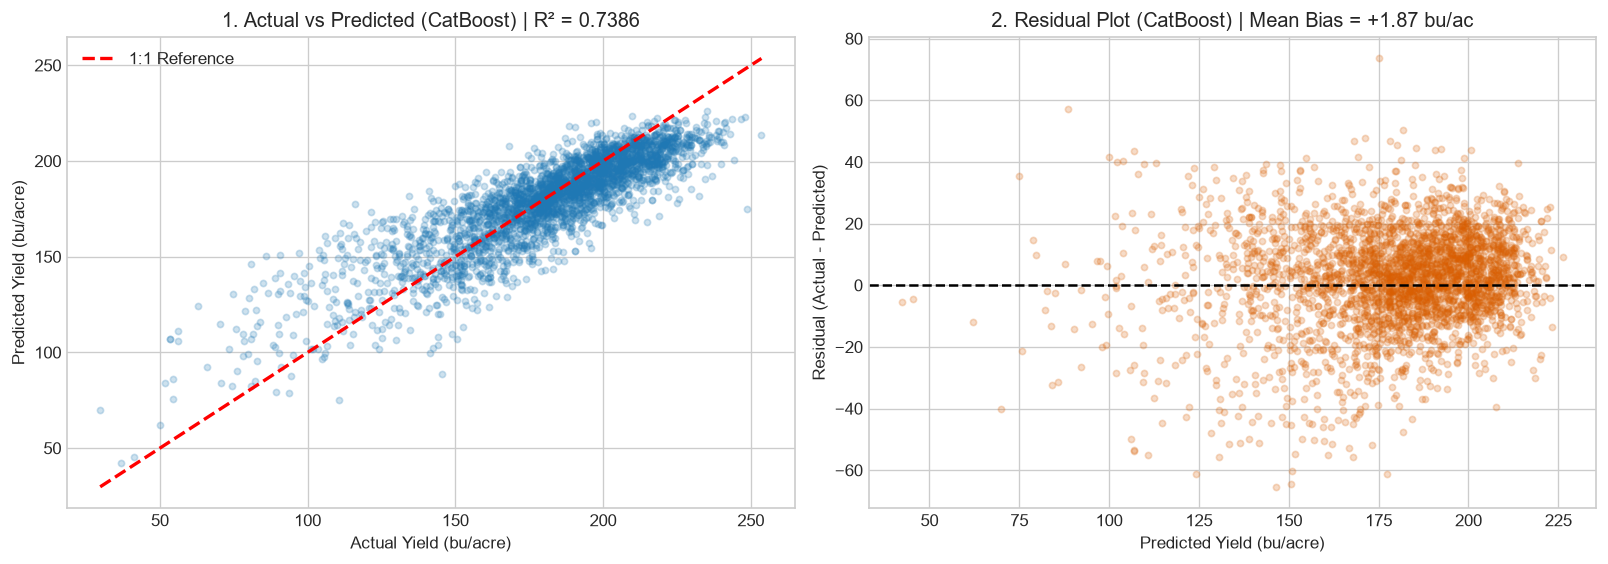

In [27]:
best_name = results_df.iloc[0]["Model"]
y_pred_best = test_preds[best_name]
residuals = y_test.values - y_pred_best

# 1. Actual vs Predicted & 2. Residual Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.8))

ax1.scatter(y_test, y_pred_best, alpha=0.22, s=14, color="#1f78b4")
lims = [min(y_test.min(), y_pred_best.min()), max(y_test.max(), y_pred_best.max())]
ax1.plot(lims, lims, "r--", lw=2, label="1:1 Reference")
ax1.set_title(f"1. Actual vs Predicted ({best_name}) | R² = {results_df.iloc[0]['Test_R2']:.4f}")
ax1.set_xlabel("Actual Yield (bu/acre)")
ax1.set_ylabel("Predicted Yield (bu/acre)")
ax1.legend()

ax2.scatter(y_pred_best, residuals, alpha=0.22, s=14, color="#d95f02")
ax2.axhline(0, color="black", linestyle="--", lw=1.5)
ax2.set_title(f"2. Residual Plot ({best_name}) | Mean Bias = {residuals.mean():+.2f} bu/ac")
ax2.set_xlabel("Predicted Yield (bu/acre)")
ax2.set_ylabel("Residual (Actual - Predicted)")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eval_actual_pred_residuals.png", dpi=130)
plt.show()

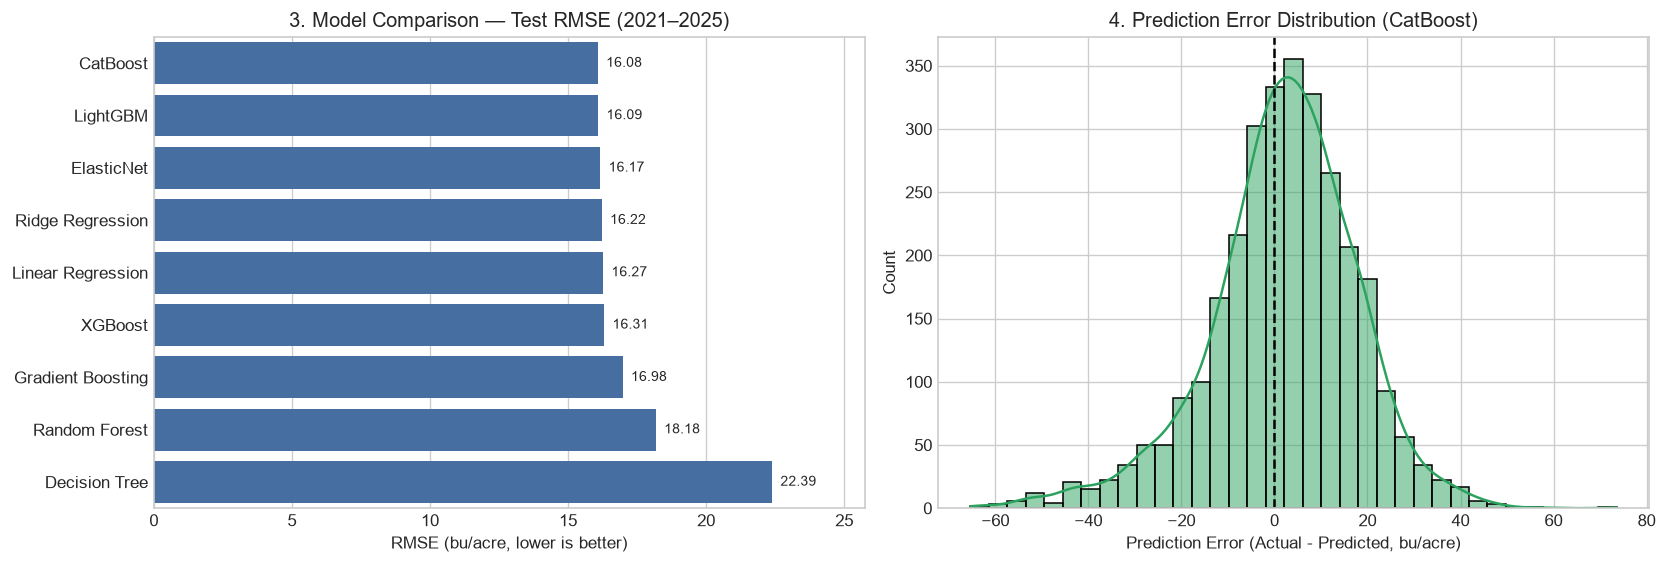

In [28]:
# 3. Model Comparison Chart & 4. Prediction Error Distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))

sns.barplot(data=results_df, y="Model", x="RMSE", color="#386cb0", ax=ax1)
ax1.set_title("3. Model Comparison — Test RMSE (2021–2025)")
ax1.set_xlabel("RMSE (bu/acre, lower is better)")
ax1.set_ylabel("")
for bar, (_, r) in zip(ax1.patches, results_df.iterrows()):
    ax1.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2, f"{r['RMSE']:.2f}", va="center", fontsize=8.5)
ax1.set_xlim(0, results_df["RMSE"].max() * 1.15)

sns.histplot(residuals, bins=35, kde=True, color="#2ca25f", ax=ax2)
ax2.axvline(0, color="black", linestyle="--")
ax2.set_title(f"4. Prediction Error Distribution ({best_name})")
ax2.set_xlabel("Prediction Error (Actual - Predicted, bu/acre)")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eval_comparison_and_error_dist.png", dpi=130)
plt.show()

,Count,MAE,RMSE
state,,,
Indiana,359,8.53,11.35
Wisconsin,309,9.82,12.39
Ohio,364,9.75,13.04
Iowa,420,10.47,13.08
Illinois,390,12.01,15.19
Minnesota,331,14.69,17.88
Nebraska,300,15.93,19.96
Missouri,303,15.45,20.32
South Dakota,217,16.89,22.06


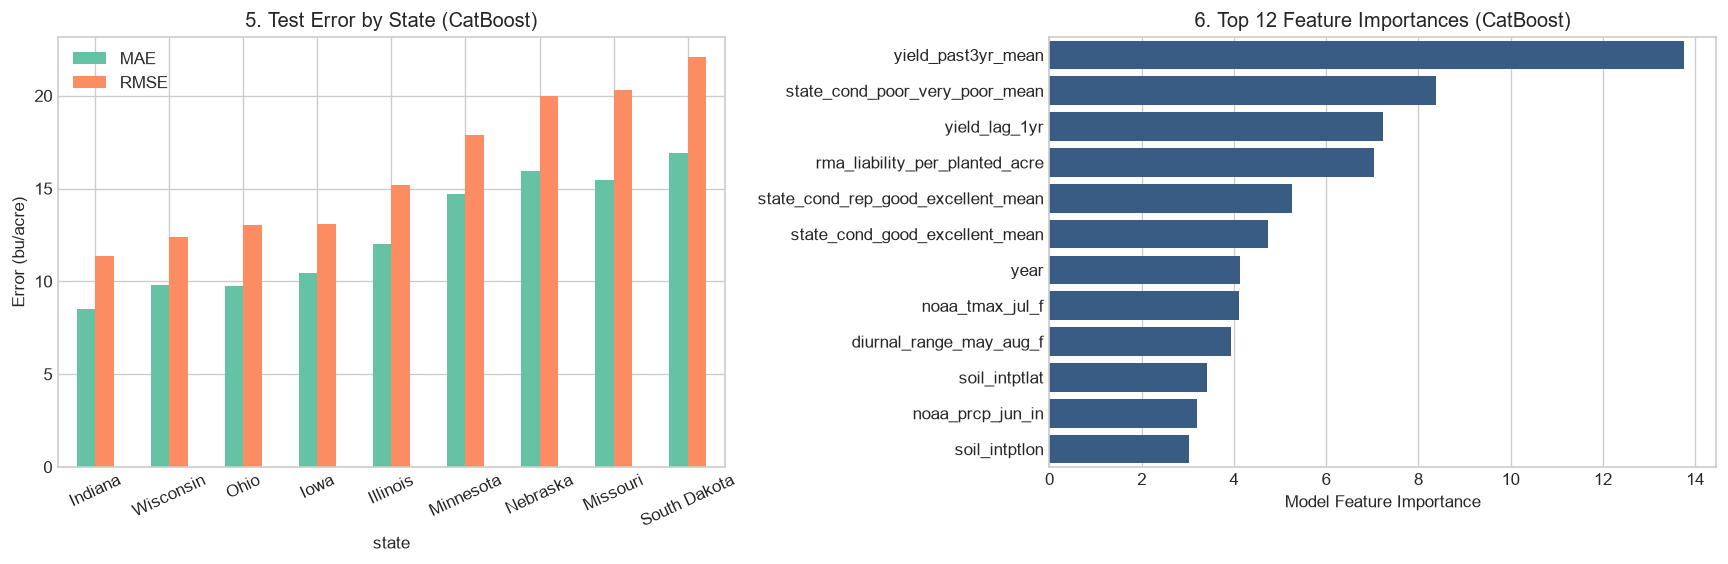

In [29]:
# 5. Error by State & 6. Feature Importance from the Top Tree-Based Model
test_eval = model_df.loc[test_mask, ["state", "year", "corn_yield_bu_acre"]].copy()
test_eval["residual"] = residuals
test_eval["abs_err"] = np.abs(residuals)
test_eval["sq_err"] = residuals ** 2

state_err = test_eval.groupby("state").agg(
    Count=("corn_yield_bu_acre", "count"),
    MAE=("abs_err", "mean"),
    RMSE=("sq_err", lambda s: np.sqrt(s.mean())),
).round(2).sort_values("RMSE")
display(state_err)

# Select best tree-based model that ran for feature_importances_
tree_names = [m for m in results_df["Model"] if m in {"CatBoost", "LightGBM", "XGBoost", "Gradient Boosting", "Random Forest", "Decision Tree"}]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 4.8))

state_err[["MAE", "RMSE"]].plot(kind="bar", color=["#66c2a5", "#fc8d62"], ax=ax1)
ax1.set_title(f"5. Test Error by State ({best_name})")
ax1.set_ylabel("Error (bu/acre)")
ax1.tick_params(axis="x", rotation=25)

if tree_names:
    top_tree = tree_names[0]
    tree_pipe = trained_pipes[top_tree]
    prep = tree_pipe.named_steps["prep"]
    est = tree_pipe.named_steps["model"]
    cat_names = list(prep.named_transformers_["cat"].named_steps["encoder"].get_feature_names_out(categorical_features))
    feat_names = numeric_features + cat_names
    imp_s = pd.Series(est.feature_importances_, index=feat_names).sort_values(ascending=False).head(12)
    sns.barplot(x=imp_s.values, y=imp_s.index, color="#2b5c8f", ax=ax2)
    ax2.set_title(f"6. Top 12 Feature Importances ({top_tree})")
    ax2.set_xlabel("Model Feature Importance")
    ax2.set_ylabel("")
else:
    ax2.axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eval_state_error_and_importance.png", dpi=130)
plt.show()

### 9.2 Supplementary Classification Demonstration (Confusion Matrix)
Predicting continuous yield (`bu/acre`) is a **regression** task, so a confusion matrix does not apply to our main models. As an **extra educational demonstration**, we convert yield into three categories (`Low Yield`, `Medium Yield`, `High Yield`) using **training-set (`2002–2020`) terciles** only, train a separate `RandomForestClassifier`, and display its confusion matrix on `2021–2025`.

Training Cutoffs: Low <= 142.40 | Medium (142.40–170.00] | High > 170.00 bu/ac
Balanced Accuracy on 2021–2025 Test: 0.6610

              precision    recall  f1-score   support

   Low Yield     0.6322    0.6341    0.6332       328
Medium Yield     0.4653    0.4429    0.4538       560
  High Yield     0.8949    0.9059    0.9004      2105

    accuracy                         0.7895      2993
   macro avg     0.6641    0.6610    0.6625      2993
weighted avg     0.7857    0.7895    0.7875      2993



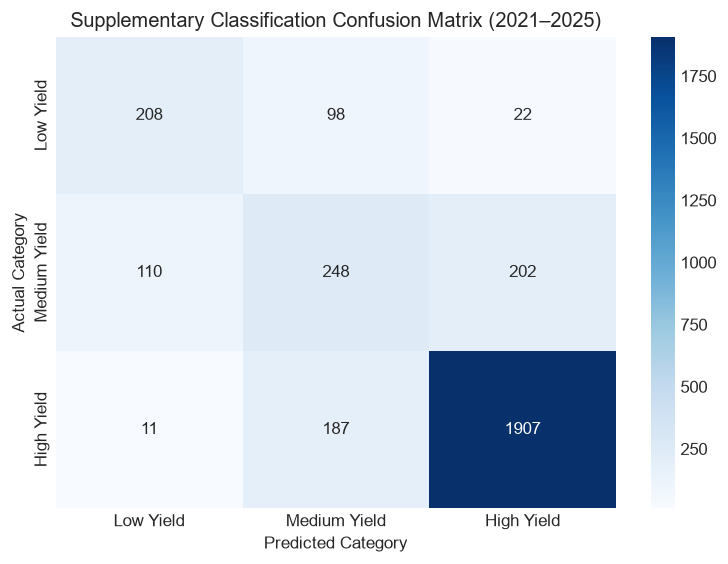

In [30]:
q33, q67 = np.quantile(y_train, [1 / 3, 2 / 3])
labels = ["Low Yield", "Medium Yield", "High Yield"]

def to_tier(arr):
    return np.where(arr <= q33, "Low Yield", np.where(arr <= q67, "Medium Yield", "High Yield"))

y_train_tier = to_tier(y_train.values)
y_test_tier = to_tier(y_test.values)

clf_pipe = Pipeline([
    ("prep", make_preprocessor(scale_numeric=False)),
    ("clf", RandomForestClassifier(n_estimators=150, max_depth=14, min_samples_leaf=5, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE)),
])
clf_pipe.fit(X_train, y_train_tier)
y_pred_tier = clf_pipe.predict(X_test)

cm = confusion_matrix(y_test_tier, y_pred_tier, labels=labels)
bal_acc = balanced_accuracy_score(y_test_tier, y_pred_tier)
print(f"Training Cutoffs: Low <= {q33:.2f} | Medium ({q33:.2f}–{q67:.2f}] | High > {q67:.2f} bu/ac")
print(f"Balanced Accuracy on 2021–2025 Test: {bal_acc:.4f}\n")
print(classification_report(y_test_tier, y_pred_tier, labels=labels, digits=4))

fig, ax = plt.subplots(figsize=(6.5, 4.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels, ax=ax)
ax.set_title("Supplementary Classification Confusion Matrix (2021–2025)")
ax.set_xlabel("Predicted Category")
ax.set_ylabel("Actual Category")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "supplementary_confusion_matrix.png", dpi=130)
plt.show()

### 9.3 Summary of Executed Results & Conclusion
The code cell below prints a clean summary directly from our executed dataframes so that all numbers stay 100% consistent with the code outputs.

In [31]:
best_row = results_df.iloc[0]
print("=== PROJECT SUMMARY (GENERATED FROM EXECUTED RESULTS) ===")
print(f"1. Integrated Dataset : {len(model_df):,} county-year rows across {model_df['county_fips'].nunique()} counties (2002–2025)")
print(f"2. Yield Range        : Min={y.min():.1f}, Mean={y.mean():.2f}, Median={y.median():.2f}, Max={y.max():.1f} bu/acre")
print(f"3. Train / Test Split : Train 2002–2020 ({len(X_train):,} rows) | Test 2021–2025 ({len(X_test):,} rows)")
print(f"4. Best Regression    : {best_row['Model']} | Test R²={best_row['Test_R2']:.4f}, MAE={best_row['MAE']:.2f}, RMSE={best_row['RMSE']:.2f} bu/acre")
print(f"5. Climate F-Test     : Partial F={f_nested:.2f}, p={p_nested:.2e} (climate features add significant signal over soil/RMA/year)")
print(f"6. Extra Classifier   : RandomForestClassifier Balanced Accuracy = {bal_acc:.4f}")

=== PROJECT SUMMARY (GENERATED FROM EXECUTED RESULTS) ===
1. Integrated Dataset : 16,390 county-year rows across 788 counties (2002–2025)
2. Yield Range        : Min=0.0, Mean=157.45, Median=161.90, Max=253.6 bu/acre
3. Train / Test Split : Train 2002–2020 (13,397 rows) | Test 2021–2025 (2,993 rows)
4. Best Regression    : CatBoost | Test R²=0.7386, MAE=12.27, RMSE=16.08 bu/acre
5. Climate F-Test     : Partial F=1099.46, p=0.00e+00 (climate features add significant signal over soil/RMA/year)
6. Extra Classifier   : RandomForestClassifier Balanced Accuracy = 0.6610


**Main Takeaways:**
- Joining multi-source tables (`USDA NASS`, `NOAA ClimDiv`, `PRISM`, `USDA RMA`, `ISRIC SoilGrids`, and `Crop Condition/Progress`) with explicit `county_fips` and `year` validation keeps row counts exact and prevents accidental duplicates.
- Extreme July heat combined with low May–August rainfall strongly reduces county maize yield, as seen in the `2012` drought and heat-group analyses.
- Testing chronologically on `2021–2025` after training on `2002–2020` avoids temporal leakage and gives a realistic measure of future-year forecasting performance.